In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving FOOD DELIVERY DATA.csv.xlsx to FOOD DELIVERY DATA.csv (1).xlsx


In [ ]:
print(uploaded.keys())


dict_keys(['FOOD DELIVERY DATA.csv (1).xlsx'])


In [ ]:
# Load the uploaded dataset
file_name = next(iter(uploaded.keys()))

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name)
elif file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)
else:
    raise ValueError("Please upload an Excel (.xlsx/.xls) or CSV (.csv) dataset.")

print(f"Dataset loaded successfully: {file_name}")
print("Original shape:", df.shape)

Dataset loaded successfully: FOOD DELIVERY DATA.csv (1).xlsx
Original shape: (20000, 31)


In [ ]:
# Basic cleaning
# Remove empty columns created during spreadsheet export
df.columns = df.columns.astype(str).str.strip()
unnamed_columns = [col for col in df.columns if col.lower().startswith("unnamed")]
if unnamed_columns:
    df = df.drop(columns=unnamed_columns)

# Convert timestamps safely.
for col in ["order_time", "delivery_time"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Derive calendar features from order_time.
if "order_time" in df.columns:
    df["order_day"] = df["order_time"].dt.day_name()
    df["order_date"] = df["order_time"].dt.date

    # Only analyze hour/time period if actual hour-level information exists.
    valid_hours = df["order_time"].dropna().dt.hour
    if not valid_hours.empty and valid_hours.nunique() > 1:
        df["order_hour"] = df["order_time"].dt.hour

        def get_time_period(hour):
            if pd.isna(hour):
                return "Unknown"
            if 6 <= hour < 12:
                return "Morning"
            elif 12 <= hour < 17:
                return "Afternoon"
            elif 17 <= hour < 22:
                return "Evening"
            return "Night"

        df["time_period"] = df["order_hour"].apply(get_time_period)
    else:
        #
        # Avoid pretending date-only values contain real order-hour information.
        df["order_hour"] = np.nan
        df["time_period"] = "Time not available"

# Create age bands for customer analysis.
if "age" in df.columns:
    def age_group(age):
        if pd.isna(age):
            return "Unknown"
        if age < 20:
            return "Under 20"
        elif age < 30:
            return "20-29"
        elif age < 40:
            return "30-39"
        elif age < 50:
            return "40-49"
        return "50+"

    df["age_group"] = df["age"].apply(age_group)

# Create delay categories. Negative delays may indicate early delivery or a
# difference in how the dataset defines delay; inspect them before interpreting.
if "delivery_delay" in df.columns:
    def categorize_delay(delay):
        if pd.isna(delay):
            return "Unknown"
        if delay <= 5:
            return "Low Delay"
        elif delay <= 15:
            return "Moderate Delay"
        return "High Delay"

    df["delay_category"] = df["delivery_delay"].apply(categorize_delay)

orders_by_hour = df["order_hour"].value_counts().sort_index() if "order_hour" in df.columns else pd.Series(dtype="int64")

print("Cleaned shape:", df.shape)
print("Derived columns added where possible: order_day, order_date, order_hour, time_period, age_group, delay_category")
print("Missing values after basic cleaning:", int(df.isnull().sum().sum()))

Cleaned shape: (20000, 36)
Derived columns added where possible: order_day, order_date, order_hour, time_period, age_group, delay_category
Missing values after basic cleaning: 20000


In [ ]:
df.head()

,order_id,restaurant_id,food_item,order_time,delivery_time,delivery_distance,order_value,delivery_method,traffic_condition,weather_condition,...,small_route,bike_friendly_route,route_type,route_efficiency,order_day,order_date,order_hour,time_period,age_group,delay_category
0,ORD000001,16,Taccos,2024-01-31,2024-01-31,2.17,42.21,Bike,Medium,Snowy,...,False,False,Bike-friendly,0.801291,Wednesday,2024-01-31,NaN,Time not available,30-39,High Delay
1,ORD000002,30,Briyani rice,2024-10-16,2024-10-16,13.40,24.82,Car,High,Sunny,...,False,False,Bike-friendly,0.645795,Wednesday,2024-10-16,NaN,Time not available,50+,High Delay
2,ORD000003,3,Pasta,2024-09-11,2024-09-11,10.74,37.25,Walk,High,Snowy,...,True,False,Bike-friendly,0.291193,Wednesday,2024-09-11,NaN,Time not available,20-29,Moderate Delay
3,ORD000004,93,Whole cake,2024-09-17,2024-09-17,6.29,49.88,Bike,High,Snowy,...,False,False,Car-only,0.133827,Tuesday,2024-09-17,NaN,Time not available,30-39,Low Delay
4,ORD000005,15,Sushi,2024-08-26,2024-08-26,2.94,8.53,Walk,Low,Sunny,...,False,True,Car-only,0.349233,Monday,2024-08-26,NaN,Time not available,20-29,Moderate Delay


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 20000
Number of columns: 36

Column names:
['order_id', 'restaurant_id', 'food_item', 'order_time', 'delivery_time', 'delivery_distance', 'order_value', 'delivery_method', 'traffic_condition', 'weather_condition', 'delivery_delay', 'route_taken', 'customer_id', 'age', 'gender', 'location', 'order_history', 'customer_rating', 'preferred_cuisine', 'order_frequency', 'loyalty_program', 'food_temperature', 'food_freshness', 'packaging_quality', 'food_condition', 'customer_satisfaction', 'small_route', 'bike_friendly_route', 'route_type', 'route_efficiency', 'order_day', 'order_date', 'order_hour', 'time_period', 'age_group', 'delay_category']


In [ ]:
df.info()
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 36 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               20000 non-null  object        
 1   restaurant_id          20000 non-null  int64         
 2   food_item              20000 non-null  object        
 3   order_time             20000 non-null  datetime64[ns]
 4   delivery_time          20000 non-null  datetime64[ns]
 5   delivery_distance      20000 non-null  float64       
 6   order_value            20000 non-null  float64       
 7   delivery_method        20000 non-null  object        
 8   traffic_condition      20000 non-null  object        
 9   weather_condition      20000 non-null  object        
 10  delivery_delay         20000 non-null  float64       
 11  route_taken            20000 non-null  object        
 12  customer_id            20000 non-null  object        
 13  a

In [ ]:
for i,column in enumerate(df.columns,start=1):
  print(f"{i}.{column}")

1.order_id
2.restaurant_id
3.food_item
4.order_time
5.delivery_time
6.delivery_distance
7.order_value
8.delivery_method
9.traffic_condition
10.weather_condition
11.delivery_delay
12.route_taken
13.customer_id
14.age
15.gender
16.location
17.order_history
18.customer_rating
19.preferred_cuisine
20.order_frequency
21.loyalty_program
22.food_temperature
23.food_freshness
24.packaging_quality
25.food_condition
26.customer_satisfaction
27.small_route
28.bike_friendly_route
29.route_type
30.route_efficiency
31.order_day
32.order_date
33.order_hour
34.time_period
35.age_group
36.delay_category


In [ ]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])
print("\n First 5 rows:")
display(df.head())
print("Last five Rows:")
display(df.tail())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 20000
Columns: 36

 First 5 rows:


,order_id,restaurant_id,food_item,order_time,delivery_time,delivery_distance,order_value,delivery_method,traffic_condition,weather_condition,...,small_route,bike_friendly_route,route_type,route_efficiency,order_day,order_date,order_hour,time_period,age_group,delay_category
0,ORD000001,16,Taccos,2024-01-31,2024-01-31,2.17,42.21,Bike,Medium,Snowy,...,False,False,Bike-friendly,0.801291,Wednesday,2024-01-31,NaN,Time not available,30-39,High Delay
1,ORD000002,30,Briyani rice,2024-10-16,2024-10-16,13.40,24.82,Car,High,Sunny,...,False,False,Bike-friendly,0.645795,Wednesday,2024-10-16,NaN,Time not available,50+,High Delay
2,ORD000003,3,Pasta,2024-09-11,2024-09-11,10.74,37.25,Walk,High,Snowy,...,True,False,Bike-friendly,0.291193,Wednesday,2024-09-11,NaN,Time not available,20-29,Moderate Delay
3,ORD000004,93,Whole cake,2024-09-17,2024-09-17,6.29,49.88,Bike,High,Snowy,...,False,False,Car-only,0.133827,Tuesday,2024-09-17,NaN,Time not available,30-39,Low Delay
4,ORD000005,15,Sushi,2024-08-26,2024-08-26,2.94,8.53,Walk,Low,Sunny,...,False,True,Car-only,0.349233,Monday,2024-08-26,NaN,Time not available,20-29,Moderate Delay


Last five Rows:


,order_id,restaurant_id,food_item,order_time,delivery_time,delivery_distance,order_value,delivery_method,traffic_condition,weather_condition,...,small_route,bike_friendly_route,route_type,route_efficiency,order_day,order_date,order_hour,time_period,age_group,delay_category
19995,ORD019996,21,Chicken wings,2024-10-27,2024-10-27,9.07,13.64,Car,Medium,Sunny,...,True,True,Bike-friendly,0.585074,Sunday,2024-10-27,NaN,Time not available,20-29,High Delay
19996,ORD019997,65,Chicken wings,2024-12-04,2024-12-04,5.41,16.71,Car,High,Sunny,...,True,True,Mixed,0.678230,Wednesday,2024-12-04,NaN,Time not available,30-39,Low Delay
19997,ORD019998,83,Shawarma,2024-10-25,2024-10-25,9.07,15.52,Bike,Medium,Sunny,...,True,True,Car-only,0.560679,Friday,2024-10-25,NaN,Time not available,30-39,High Delay
19998,ORD019999,13,Shawarma,2024-10-02,2024-10-02,13.48,16.49,Car,Medium,Snowy,...,False,True,Mixed,0.624297,Wednesday,2024-10-02,NaN,Time not available,40-49,Low Delay
19999,ORD020000,26,Pasta,2024-02-14,2024-02-14,14.23,37.31,Bike,High,Sunny,...,False,True,Car-only,0.161206,Wednesday,2024-02-14,NaN,Time not available,30-39,High Delay


Number of rows: 20000
Number of columns: 36

Column names:
['order_id', 'restaurant_id', 'food_item', 'order_time', 'delivery_time', 'delivery_distance', 'order_value', 'delivery_method', 'traffic_condition', 'weather_condition', 'delivery_delay', 'route_taken', 'customer_id', 'age', 'gender', 'location', 'order_history', 'customer_rating', 'preferred_cuisine', 'order_frequency', 'loyalty_program', 'food_temperature', 'food_freshness', 'packaging_quality', 'food_condition', 'customer_satisfaction', 'small_route', 'bike_friendly_route', 'route_type', 'route_efficiency', 'order_day', 'order_date', 'order_hour', 'time_period', 'age_group', 'delay_category']
Number of rows: 20000
Number of columns: 36

Column names:
['order_id', 'restaurant_id', 'food_item', 'order_time', 'delivery_time', 'delivery_distance', 'order_value', 'delivery_method', 'traffic_condition', 'weather_condition', 'delivery_delay', 'route_taken', 'customer_id', 'age', 'gender', 'location', 'order_history', 'customer_rat

In [ ]:
df.describe()


,restaurant_id,order_time,delivery_time,delivery_distance,order_value,delivery_delay,age,order_history,customer_rating,food_freshness,packaging_quality,customer_satisfaction,route_efficiency,order_hour
count,20000.000000,20000,20000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,0.0
mean,50.528000,2024-06-22 20:53:31.200000,2024-06-22 20:53:31.200000,8.498350,27.335090,4.952421,38.925300,25.751400,3.026800,2.991700,3.003400,2.976300,0.496246,NaN
min,1.000000,2024-01-01 00:00:00,2024-01-01 00:00:00,2.000000,5.000000,-10.000000,18.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000276,NaN
25%,26.000000,2024-03-29 00:00:00,2024-03-29 00:00:00,5.220000,15.960000,-2.430000,28.000000,13.000000,2.000000,2.000000,2.000000,2.000000,0.245070,NaN
50%,51.000000,2024-06-24 00:00:00,2024-06-24 00:00:00,8.470000,27.200000,4.900000,39.000000,26.000000,3.000000,3.000000,3.000000,3.000000,0.494741,NaN
75%,75.000000,2024-09-17 00:00:00,2024-09-17 00:00:00,11.810000,38.712500,12.320000,50.000000,38.000000,4.000000,4.000000,4.000000,4.000000,0.742996,NaN
max,100.000000,2024-12-12 00:00:00,2024-12-12 00:00:00,15.000000,49.990000,20.000000,60.000000,50.000000,5.000000,5.000000,5.000000,5.000000,0.999841,NaN
std,28.715004,NaN,NaN,3.768308,13.026475,8.624563,12.370941,14.311731,1.416468,1.415744,1.416929,1.415217,0.287044,NaN


In [ ]:
categorical_columns = [
    "food_item",
    "delivery_mode",
    "traffic_condition",
    "weather_condition",
    "gender",
    "location",
    "preferred_cuisine",
    "loyalty_program",
    "food_temperature",
    "food_freshness",
    "packaging",
    "food_condition",
    "route_type"
]

for column in categorical_columns:
    if column in df.columns:
        print("\n==============================")
        print(column)
        print("==============================")
        print(df[column].value_counts())


food_item
food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Chicken pie        910
Taccos             906
Salad              896
Fried chicken      894
Briyani rice       890
Dumplings          888
Sushi              878
Shawarma           874
Burger             866
PastrySmoothie     862
Burritos           848
Name: count, dtype: int64

traffic_condition
traffic_condition
Low       6772
Medium    6700
High      6528
Name: count, dtype: int64

weather_condition
weather_condition
Snowy    6728
Sunny    6672
Rainy    6600
Name: count, dtype: int64

gender
gender
Other     6778
Female    6656
Male      6566
Name: count, dtype: int64

location
location
Ahmedabad    2051
Kolkata      2032
Delhi        2027
Pune         2026
Jaipur       2013
Chennai      1998
Mumbai       1980
Hyderabad    1973
Bangalor

In [ ]:
for column in df.columns:
  print(f"{column}:{df[column].nunique()}unique values")


order_id:20000unique values
restaurant_id:100unique values
food_item:21unique values
order_time:347unique values
delivery_time:347unique values
delivery_distance:1301unique values
order_value:4026unique values
delivery_method:3unique values
traffic_condition:3unique values
weather_condition:3unique values
delivery_delay:2905unique values
route_taken:5unique values
customer_id:20000unique values
age:43unique values
gender:3unique values
location:10unique values
order_history:50unique values
customer_rating:5unique values
preferred_cuisine:5unique values
order_frequency:2unique values
loyalty_program:2unique values
food_temperature:3unique values
food_freshness:5unique values
packaging_quality:5unique values
food_condition:3unique values
customer_satisfaction:5unique values
small_route:2unique values
bike_friendly_route:2unique values
route_type:3unique values
route_efficiency:10000unique values
order_day:7unique values
order_date:347unique values
order_hour:0unique values
time_period:1u

In [ ]:
#checking the duplicates
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


In [ ]:
#checking the missing data properly
missing=df.isnull().sum()
missing=missing[missing>0].sort_values(ascending=False)
print(missing)

order_hour    20000
dtype: int64


In [ ]:
#calculating the perentage
missing_percentage=(df.isnull().sum()/len(df))*100
missing_percentage=(
    missing_percentage[missing_percentage>0].sort_values(ascending=False)
)
print(missing_percentage
)

order_hour    100.0
dtype: float64


In [ ]:
#cleaning the data properly
print(df.dtypes)


order_id                         object
restaurant_id                     int64
food_item                        object
order_time               datetime64[ns]
delivery_time            datetime64[ns]
delivery_distance               float64
order_value                     float64
delivery_method                  object
traffic_condition                object
weather_condition                object
delivery_delay                  float64
route_taken                      object
customer_id                      object
age                               int64
gender                           object
location                         object
order_history                     int64
customer_rating                   int64
preferred_cuisine                object
order_frequency                  object
loyalty_program                  object
food_temperature                 object
food_freshness                    int64
packaging_quality                 int64
food_condition                   object


In [ ]:
print("Order time range:")
print("Start:", df["order_time"].min())
print("End:", df["order_time"].max())

print("\nDelivery time range:")
print("Start:", df["delivery_time"].min())
print("End:", df["delivery_time"].max())

Order time range:
Start: 2024-01-01 00:00:00
End: 2024-12-12 00:00:00

Delivery time range:
Start: 2024-01-01 00:00:00
End: 2024-12-12 00:00:00


In [ ]:
print(df[[
    "delivery_distance",
    "order_value",
    "delivery_delay",
    "route_efficiency"
]].describe())


       delivery_distance   order_value  delivery_delay  route_efficiency
count       20000.000000  20000.000000    20000.000000      20000.000000
mean            8.498350     27.335090        4.952421          0.496246
std             3.768308     13.026475        8.624563          0.287044
min             2.000000      5.000000      -10.000000          0.000276
25%             5.220000     15.960000       -2.430000          0.245070
50%             8.470000     27.200000        4.900000          0.494741
75%            11.810000     38.712500       12.320000          0.742996
max            15.000000     49.990000       20.000000          0.999841


In [ ]:
important_categorical = [
    "food_item",
    "delivery_method",
    "traffic_condition",
    "weather_condition",
    "location",
    "preferred_cuisine",
    "order_frequency",
    "loyalty_program",
    "food_temperature",
    "food_condition",
    "route_type"
]

for column in important_categorical:
    print("\n" + "=" * 40)
    print(column)
    print("=" * 40)
    print(df[column].value_counts(dropna=False))



food_item
food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Chicken pie        910
Taccos             906
Salad              896
Fried chicken      894
Briyani rice       890
Dumplings          888
Sushi              878
Shawarma           874
Burger             866
PastrySmoothie     862
Burritos           848
Name: count, dtype: int64

delivery_method
delivery_method
Walk    6830
Bike    6598
Car     6572
Name: count, dtype: int64

traffic_condition
traffic_condition
Low       6772
Medium    6700
High      6528
Name: count, dtype: int64

weather_condition
weather_condition
Snowy    6728
Sunny    6672
Rainy    6600
Name: count, dtype: int64

location
location
Ahmedabad    2051
Kolkata      2032
Delhi        2027
Pune         2026
Jaipur       2013
Chennai      1998
Mumbai       1980
Hyderabad    1

In [ ]:
print("Small route:")
print(df["small_route"].value_counts())

print("\nBike-friendly route:")
print(df["bike_friendly_route"].value_counts())


Small route:
small_route
True     10080
False     9920
Name: count, dtype: int64

Bike-friendly route:
bike_friendly_route
False    10074
True      9926
Name: count, dtype: int64


In [ ]:
# Check the unwanted column
print("New shape:", df.shape)
#print("Total rows:", len(df))
print("Unique orders:", df["order_id"].nunique())
print("Duplicate order IDs:", df["order_id"].duplicated().sum())

New shape: (20000, 36)
Unique orders: 20000
Duplicate order IDs: 0


In [ ]:
# Numeric and categorical overview
numeric_columns = [
    "delivery_distance", "order_value", "delivery_delay", "age",
    "order_history", "customer_rating", "food_freshness",
    "packaging_quality", "customer_satisfaction", "route_efficiency"
]
numeric_columns = [col for col in numeric_columns if col in df.columns]
display(df[numeric_columns].describe())

for column in numeric_columns:
    print(f"{column}: min = {df[column].min()}, max = {df[column].max()}")

categorical_columns = [
    "food_item", "delivery_method", "traffic_condition", "weather_condition",
    "gender", "location", "preferred_cuisine", "order_frequency",
    "loyalty_program", "food_temperature", "food_condition", "route_type"
]
for column in categorical_columns:
    if column in df.columns:
        print("\\n" + "=" * 50)
        print(column)
        print("=" * 50)
        print(df[column].value_counts(dropna=False))

route_columns = [
    "small_route", "bike_friendly_route", "route_type",
    "route_efficiency", "route_taken"
]
for column in route_columns:
    if column in df.columns:
        print("\\n" + "=" * 40)
        print(column)
        print("=" * 40)
        print("Data type:", df[column].dtype)
        print(df[column].value_counts(dropna=False).head(20))

print("\\nOrder time range:")
if "order_time" in df.columns:
    print("Earliest:", df["order_time"].min())
    print("Latest:", df["order_time"].max())
print("\\nDelivery time range:")
if "delivery_time" in df.columns:
    print("Earliest:", df["delivery_time"].min())
    print("Latest:", df["delivery_time"].max())

,delivery_distance,order_value,delivery_delay,age,order_history,customer_rating,food_freshness,packaging_quality,customer_satisfaction,route_efficiency
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,8.498350,27.335090,4.952421,38.925300,25.751400,3.026800,2.991700,3.003400,2.976300,0.496246
std,3.768308,13.026475,8.624563,12.370941,14.311731,1.416468,1.415744,1.416929,1.415217,0.287044
min,2.000000,5.000000,-10.000000,18.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000276
25%,5.220000,15.960000,-2.430000,28.000000,13.000000,2.000000,2.000000,2.000000,2.000000,0.245070
50%,8.470000,27.200000,4.900000,39.000000,26.000000,3.000000,3.000000,3.000000,3.000000,0.494741
75%,11.810000,38.712500,12.320000,50.000000,38.000000,4.000000,4.000000,4.000000,4.000000,0.742996
max,15.000000,49.990000,20.000000,60.000000,50.000000,5.000000,5.000000,5.000000,5.000000,0.999841


delivery_distance: min = 2.0, max = 15.0
order_value: min = 5.0, max = 49.99
delivery_delay: min = -10.0, max = 20.0
age: min = 18, max = 60
order_history: min = 1, max = 50
customer_rating: min = 1, max = 5
food_freshness: min = 1, max = 5
packaging_quality: min = 1, max = 5
customer_satisfaction: min = 1, max = 5
route_efficiency: min = 0.0002762870274076, max = 0.9998409602175802
\n==================================================
food_item
food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Chicken pie        910
Taccos             906
Salad              896
Fried chicken      894
Briyani rice       890
Dumplings          888
Sushi              878
Shawarma           874
Burger             866
PastrySmoothie     862
Burritos           848
Name: count, dtype: int64
\n==============================

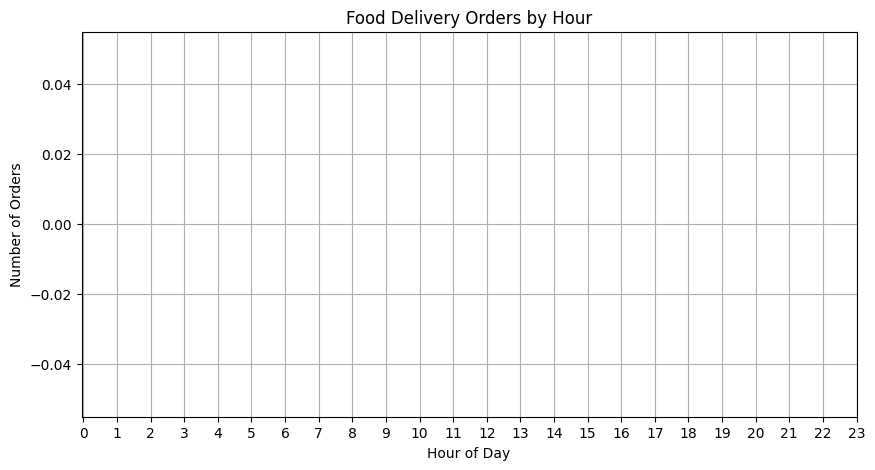

time_period
Time not available    20000
Name: count, dtype: int64


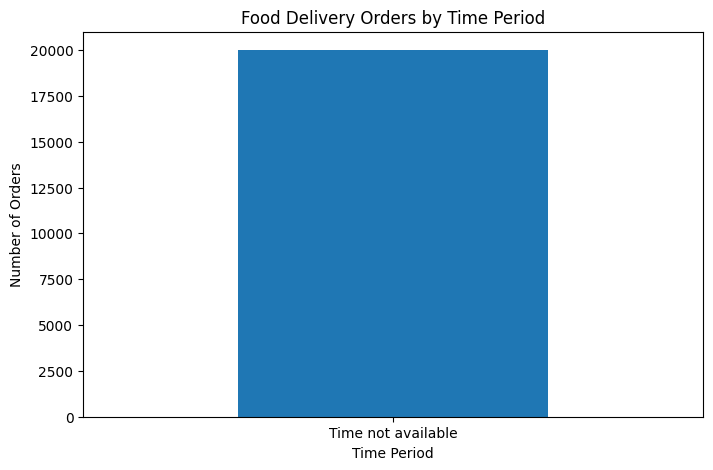

In [ ]:
#visualisation
plt.figure(figsize=(10, 5))

plt.plot(
    orders_by_hour.index,
    orders_by_hour.values,
    marker="o"
)

plt.title("Food Delivery Orders by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(True)

plt.show()
orders_by_period = df["time_period"].value_counts()

print(orders_by_period)
plt.figure(figsize=(8, 5))

orders_by_period.plot(kind="bar")

plt.title("Food Delivery Orders by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()


In [ ]:
#analysing demand by day
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

orders_by_day = df["order_day"].value_counts().reindex(day_order)

print(orders_by_day)

order_day
Monday       2878
Tuesday      2786
Wednesday    2926
Thursday     3062
Friday       2756
Saturday     2782
Sunday       2810
Name: count, dtype: int64


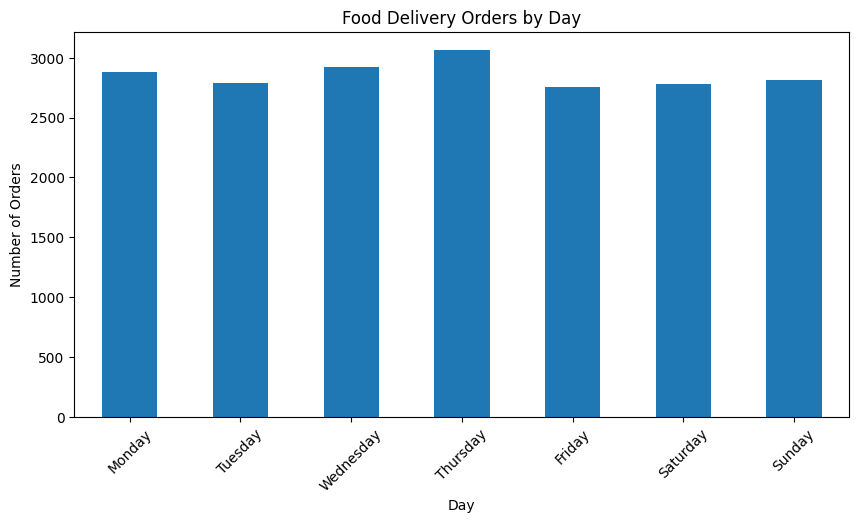

In [ ]:
plt.figure(figsize=(10, 5))

orders_by_day.plot(kind="bar")

plt.title("Food Delivery Orders by Day")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#food demand and revenue analysis
food_demand = df["food_item"].value_counts()

print(food_demand)

food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Chicken pie        910
Taccos             906
Salad              896
Fried chicken      894
Briyani rice       890
Dumplings          888
Sushi              878
Shawarma           874
Burger             866
PastrySmoothie     862
Burritos           848
Name: count, dtype: int64


In [ ]:
#most popular food
food_demand = df["food_item"].value_counts()

print(food_demand)

food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Chicken pie        910
Taccos             906
Salad              896
Fried chicken      894
Briyani rice       890
Dumplings          888
Sushi              878
Shawarma           874
Burger             866
PastrySmoothie     862
Burritos           848
Name: count, dtype: int64


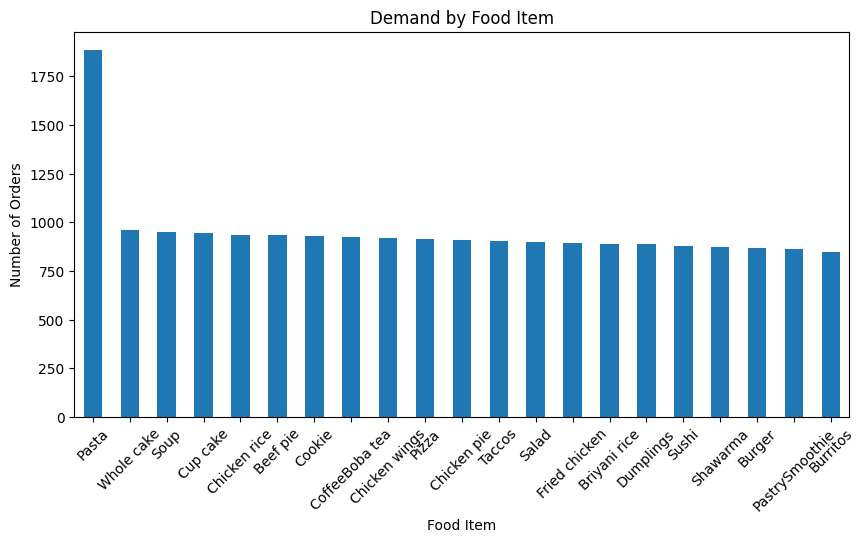

In [ ]:
plt.figure(figsize=(10, 5))

food_demand.plot(kind="bar")

plt.title("Demand by Food Item")
plt.xlabel("Food Item")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#printing the top 10 food items
top_food = df["food_item"].value_counts().head(10)

print(top_food)

food_item
Pasta             1884
Whole cake         958
Soup               948
Cup cake           944
Chicken rice       934
Beef pie           934
Cookie             930
CoffeeBoba tea     922
Chicken wings      918
Pizza              916
Name: count, dtype: int64


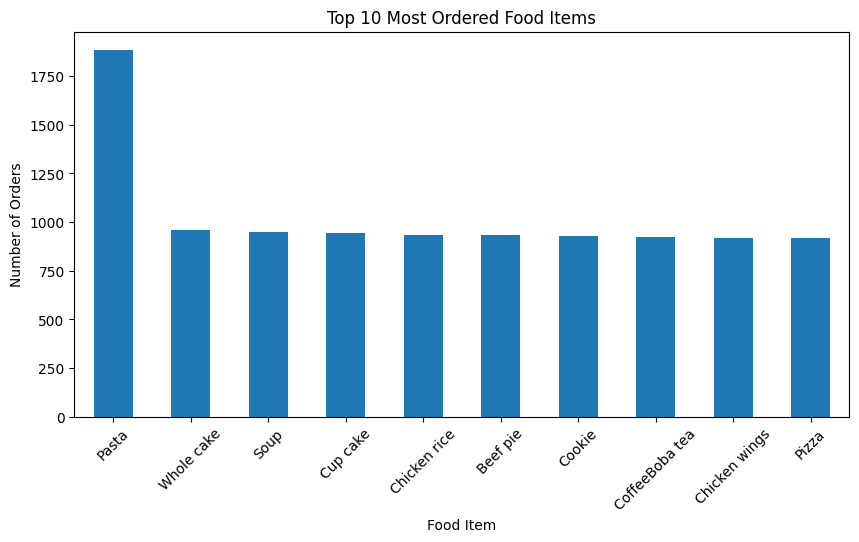

In [ ]:
plt.figure(figsize=(10, 5))

top_food.plot(kind="bar")

plt.title("Top 10 Most Ordered Food Items")
plt.xlabel("Food Item")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
location_demand = df["location"].value_counts()

print(location_demand)

location
Ahmedabad    2051
Kolkata      2032
Delhi        2027
Pune         2026
Jaipur       2013
Chennai      1998
Mumbai       1980
Hyderabad    1973
Bangalore    1968
Lucknow      1932
Name: count, dtype: int64


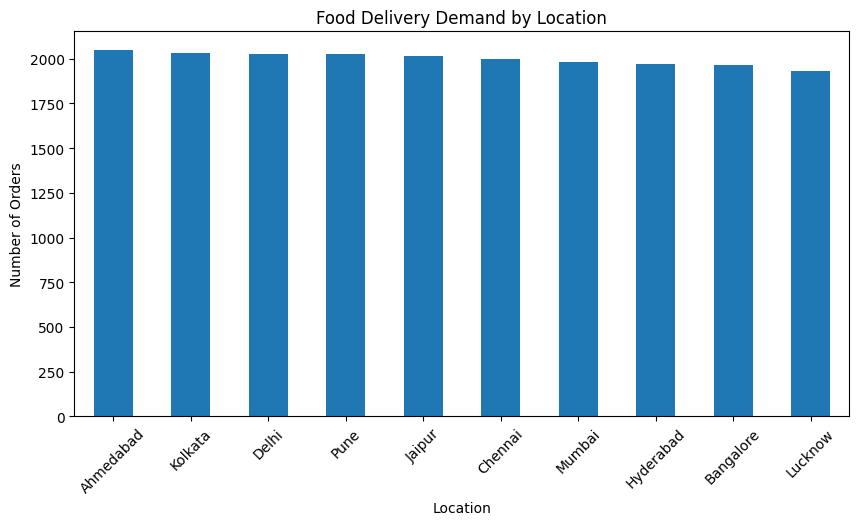

In [ ]:
plt.figure(figsize=(10, 5))

location_demand.plot(kind="bar")

plt.title("Food Delivery Demand by Location")
plt.xlabel("Location")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#analysing the revenue
print("Average order value:", df["order_value"].mean())
print("Median order value:", df["order_value"].median())
print("Minimum order value:", df["order_value"].min())
print("Maximum order value:", df["order_value"].max())

Average order value: 27.33509
Median order value: 27.2
Minimum order value: 5.0
Maximum order value: 49.99


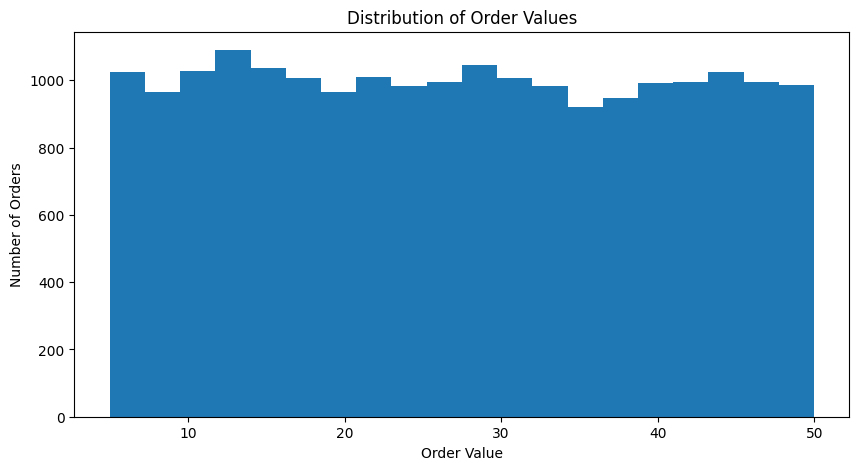

In [ ]:
#distribution of order values
plt.figure(figsize=(10, 5))

plt.hist(df["order_value"], bins=20)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

In [ ]:
#avERAGE VALUE OF THE FOOD ITEM
avg_value_by_food = (
    df.groupby("food_item")["order_value"]
      .mean()
      .sort_values(ascending=False)
)

print(avg_value_by_food)


food_item
Fried chicken     28.343311
Shawarma          27.922883
Cup cake          27.921886
Pizza             27.899105
Pasta             27.717580
Chicken rice      27.690000
CoffeeBoba tea    27.648742
Chicken pie       27.422505
Cookie            27.347699
Beef pie          27.256638
Taccos            27.198234
Dumplings         27.174234
PastrySmoothie    27.160835
Burger            27.064249
Chicken wings     27.002353
Whole cake        26.957891
Sushi             26.953531
Salad             26.837835
Soup              26.823101
Briyani rice      26.665528
Burritos          26.551226
Name: order_value, dtype: float64


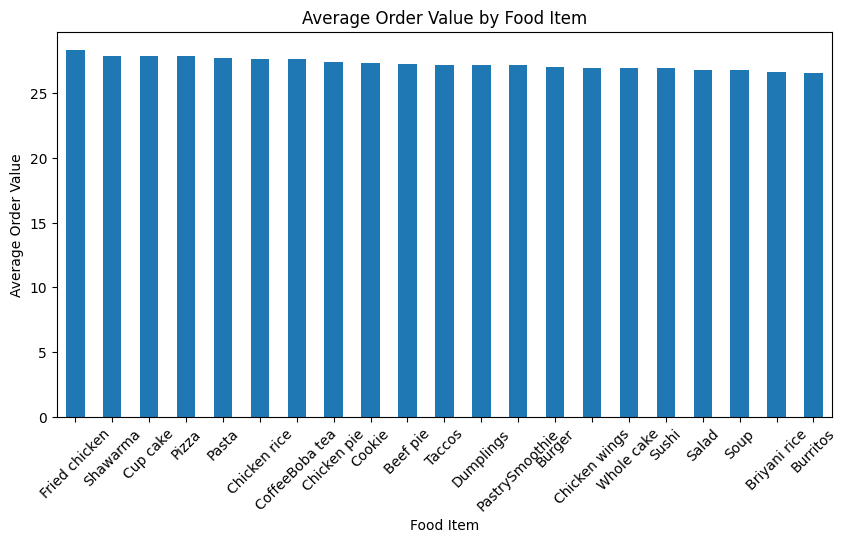

In [ ]:
plt.figure(figsize=(10, 5))

avg_value_by_food.plot(kind="bar")

plt.title("Average Order Value by Food Item")
plt.xlabel("Food Item")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)

plt.show()

In [ ]:
print("Average delivery distance:",
      df["delivery_distance"].mean())

print("Average delivery delay:",
      df["delivery_delay"].mean())

print("Maximum delivery distance:",
      df["delivery_distance"].max())

print("Maximum delivery delay:",
      df["delivery_delay"].max())

Average delivery distance: 8.49835
Average delivery delay: 4.952421
Maximum delivery distance: 15.0
Maximum delivery delay: 20.0


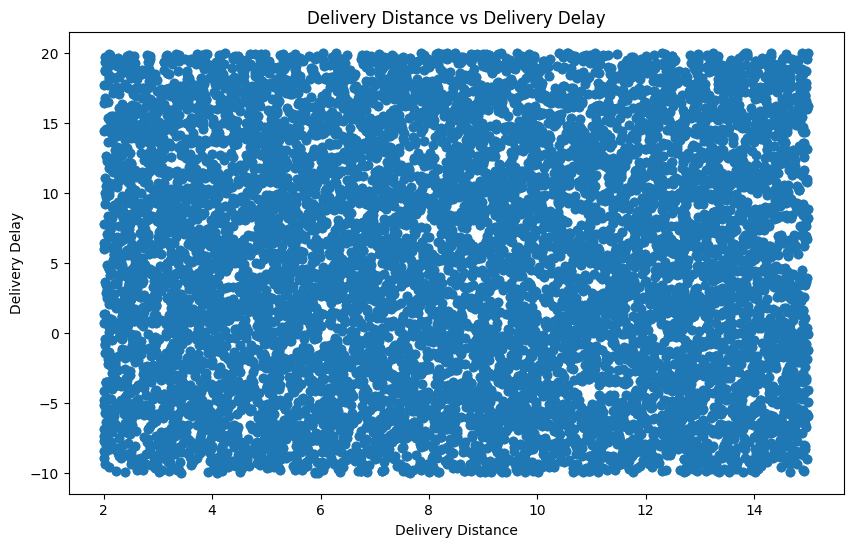

In [ ]:
#DISTANCE VERSUS THE DELIVERY DELAY
#RELATIONSHIP ANALYSIS
plt.figure(figsize=(10, 6))

plt.scatter(
    df["delivery_distance"],
    df["delivery_delay"]
)

plt.title("Delivery Distance vs Delivery Delay")
plt.xlabel("Delivery Distance")
plt.ylabel("Delivery Delay")

plt.show()

In [ ]:
#TRAFFIC CONDITION VERSUS THE DELIVERY DELAY
traffic_delay = (
    df.groupby("traffic_condition")["delivery_delay"]
      .mean()
      .sort_values()
)

print(traffic_delay)

traffic_condition
Medium    4.824349
High      4.980852
Low       5.051725
Name: delivery_delay, dtype: float64


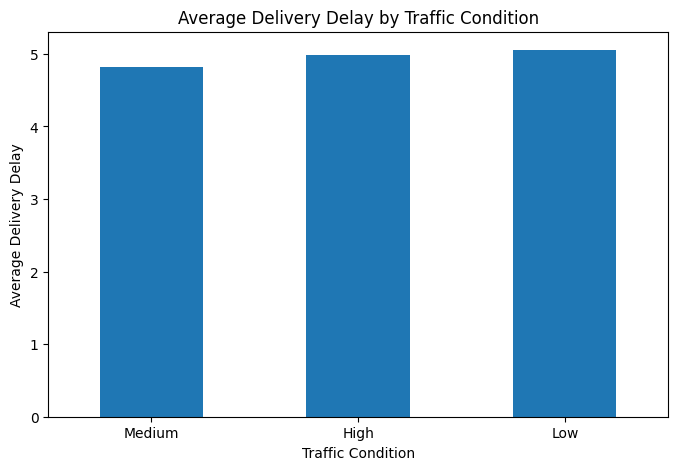

In [ ]:
#VISUALISING THE SAME
plt.figure(figsize=(8, 5))

traffic_delay.plot(kind="bar")

plt.title("Average Delivery Delay by Traffic Condition")
plt.xlabel("Traffic Condition")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=0)

plt.show()

In [ ]:
#WEATHER DAY VERSUS THE DELIVERY
weather_delay = (
    df.groupby("weather_condition")["delivery_delay"]
      .mean()
      .sort_values()
)

print(weather_delay)

weather_condition
Rainy    4.872745
Snowy    4.950746
Sunny    5.032926
Name: delivery_delay, dtype: float64


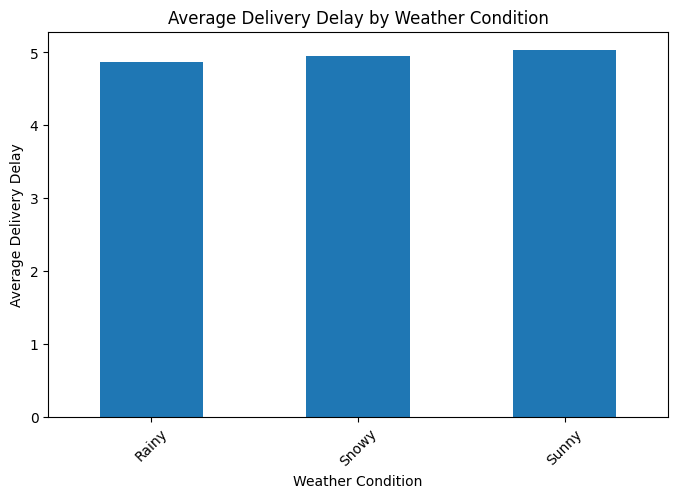

In [ ]:
plt.figure(figsize=(8, 5))

weather_delay.plot(kind="bar")

plt.title("Average Delivery Delay by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#DELIVERY METHOD DISTRIBUTION
delivery_methods = df["delivery_method"].value_counts()

print(delivery_methods)

delivery_method
Walk    6830
Bike    6598
Car     6572
Name: count, dtype: int64


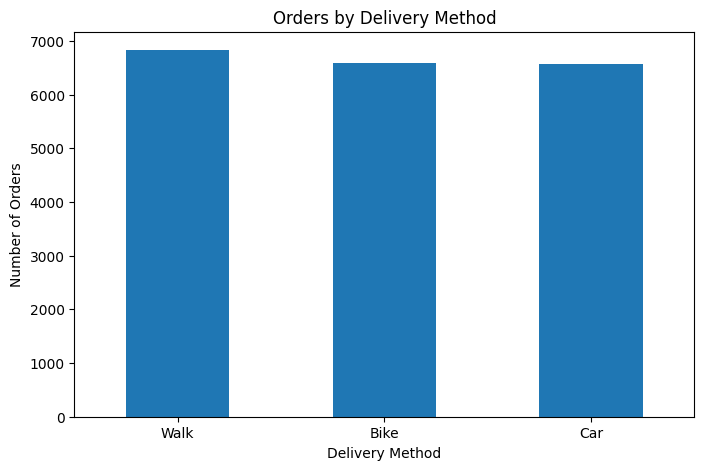

In [ ]:
#VISULALISING THE SAME
plt.figure(figsize=(8, 5))

delivery_methods.plot(kind="bar")

plt.title("Orders by Delivery Method")
plt.xlabel("Delivery Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

In [ ]:
#DELIVERY METHOD VERSUS THE DELAY DELIVERY
method_delay = (
    df.groupby("delivery_method")["delivery_delay"]
      .mean()
      .sort_values()
)

print(method_delay)

delivery_method
Walk    4.701865
Bike    4.951679
Car     5.213558
Name: delivery_delay, dtype: float64


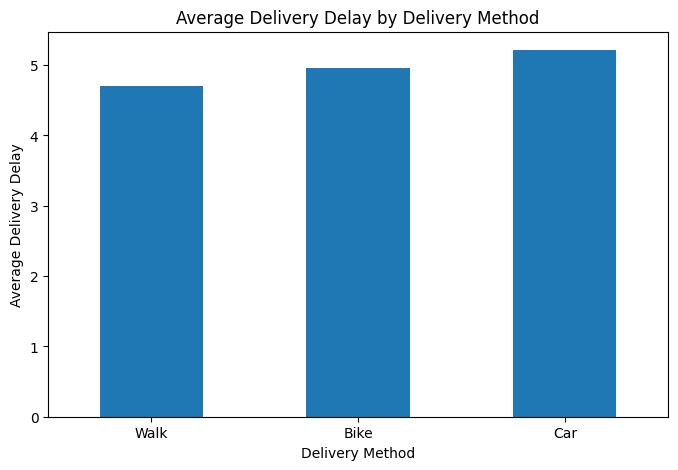

In [ ]:
#VISUALISING THE SAME
plt.figure(figsize=(8, 5))

method_delay.plot(kind="bar")

plt.title("Average Delivery Delay by Delivery Method")
plt.xlabel("Delivery Method")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=0)

plt.show()

In [ ]:
#ROUTE ANALYSIS
print(df["route_type"].value_counts(dropna=False))

route_type
Mixed            6794
Bike-friendly    6608
Car-only         6598
Name: count, dtype: int64


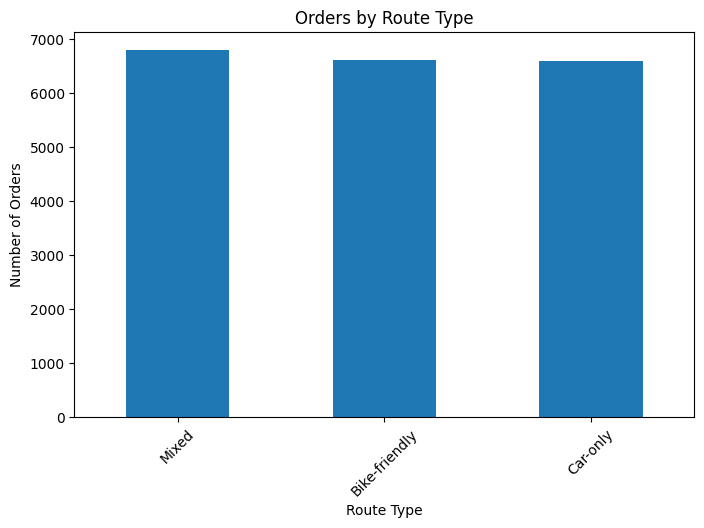

In [ ]:
plt.figure(figsize=(8, 5))

df["route_type"].value_counts().plot(kind="bar")

plt.title("Orders by Route Type")
plt.xlabel("Route Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

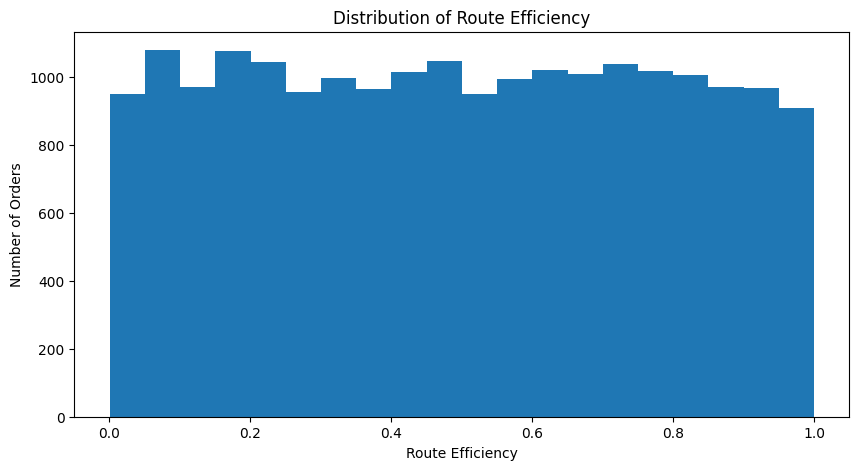

In [ ]:
#ROUTE EFICIENY DISTRIBUTION
plt.figure(figsize=(10, 5))

plt.hist(df["route_efficiency"], bins=20)

plt.title("Distribution of Route Efficiency")
plt.xlabel("Route Efficiency")
plt.ylabel("Number of Orders")

plt.show()

route_type
Bike-friendly    0.500521
Mixed            0.499932
Car-only         0.488170
Name: route_efficiency, dtype: float64


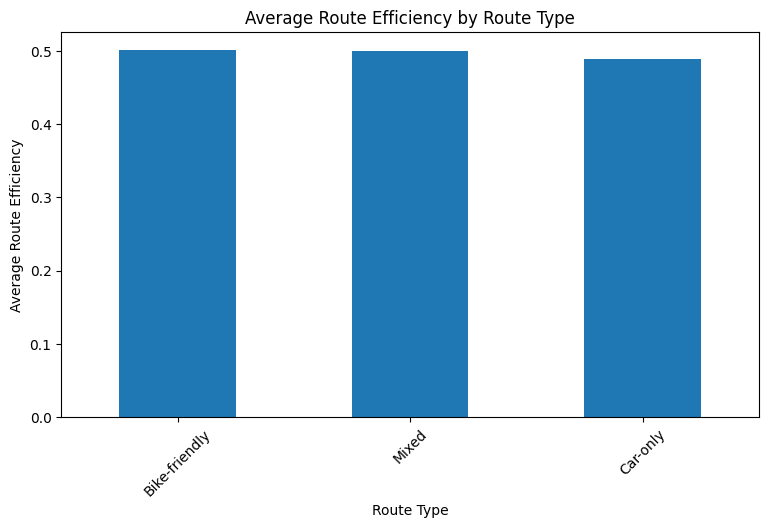

In [ ]:
route_efficiency = (
    df.groupby("route_type")["route_efficiency"]
      .mean()
      .sort_values(ascending=False)
)

print(route_efficiency)
plt.figure(figsize=(9, 5))

route_efficiency.plot(kind="bar")

plt.title("Average Route Efficiency by Route Type")
plt.xlabel("Route Type")
plt.ylabel("Average Route Efficiency")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#ROUTE TYOE VERSUS THE DELIVERY DELAY
route_delay = (
    df.groupby("route_type")["delivery_delay"]
      .mean()
      .sort_values()
)

print(route_delay)

route_type
Mixed            4.779014
Bike-friendly    4.983647
Car-only         5.099706
Name: delivery_delay, dtype: float64


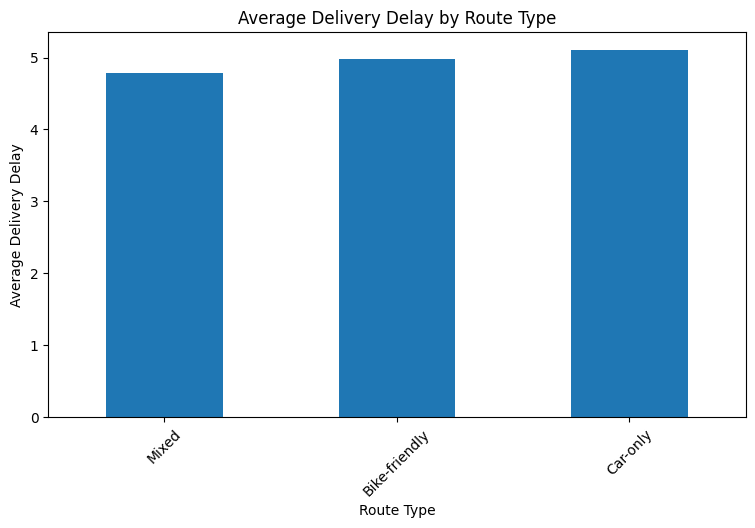

In [ ]:
plt.figure(figsize=(9, 5))

route_delay.plot(kind="bar")

plt.title("Average Delivery Delay by Route Type")
plt.xlabel("Route Type")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=45)

plt.show()

In [ ]:
print("Small route:")
print(df["small_route"].value_counts())

print("\nBike-friendly route:")
print(df["bike_friendly_route"].value_counts())
#SMALL ROUTE VERSUS THE DELAY
small_route_delay = (
    df.groupby("small_route")["delivery_delay"]
      .mean()
)

print(small_route_delay)

Small route:
small_route
True     10080
False     9920
Name: count, dtype: int64

Bike-friendly route:
bike_friendly_route
False    10074
True      9926
Name: count, dtype: int64
small_route
False    5.015093
True     4.890744
Name: delivery_delay, dtype: float64


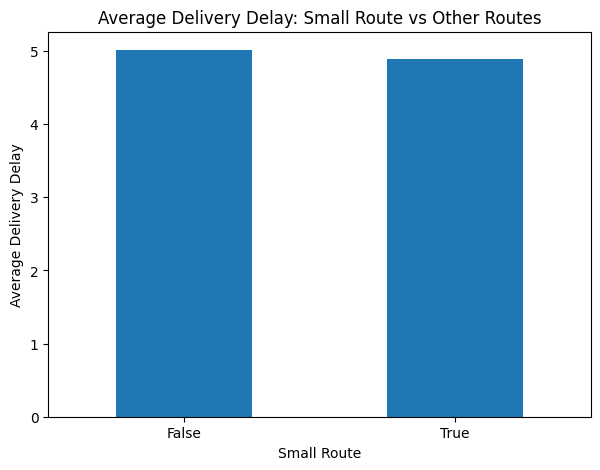

In [ ]:
plt.figure(figsize=(7, 5))

small_route_delay.plot(kind="bar")

plt.title("Average Delivery Delay: Small Route vs Other Routes")
plt.xlabel("Small Route")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=0)

plt.show()

In [ ]:
#BIKE FRIENDLY ROUTE VERSUS THE DELAY
bike_route_delay = (
    df.groupby("bike_friendly_route")["delivery_delay"]
      .mean()
)

print(bike_route_delay)

bike_friendly_route
False    4.940187
True     4.964838
Name: delivery_delay, dtype: float64


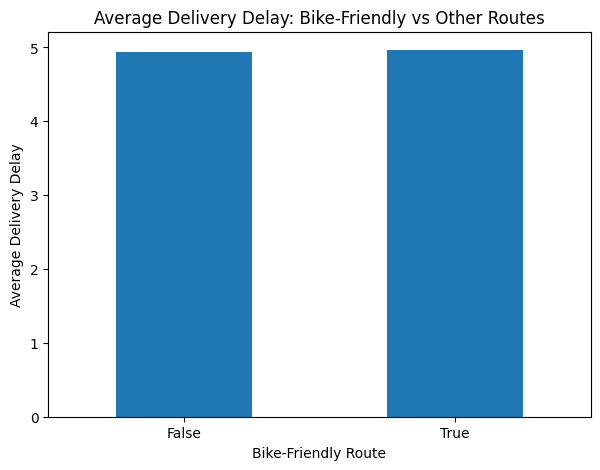

In [ ]:
plt.figure(figsize=(7, 5))

bike_route_delay.plot(kind="bar")

plt.title("Average Delivery Delay: Bike-Friendly vs Other Routes")
plt.xlabel("Bike-Friendly Route")
plt.ylabel("Average Delivery Delay")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# Route analysis: count orders by recorded route
if "route_taken" in df.columns:
    print(df["route_taken"].value_counts(dropna=False))
else:
    print("The dataset does not contain a 'route_taken' column.")

route_taken
Route_5    4136
Route_1    4114
Route_4    3974
Route_3    3892
Route_2    3884
Name: count, dtype: int64


In [ ]:
# Average delivery delay by recorded route
if "route_taken" in df.columns:
    route_taken_delay = (
        df.groupby("route_taken")["delivery_delay"]
          .mean()
          .sort_values()
    )
    display(route_taken_delay)
else:
    print("Route-level delay analysis skipped: 'route_taken' is not available.")

,delivery_delay
route_taken,
Route_3,4.783690
Route_1,4.851872
Route_4,4.979270
Route_2,5.047472
Route_5,5.096156


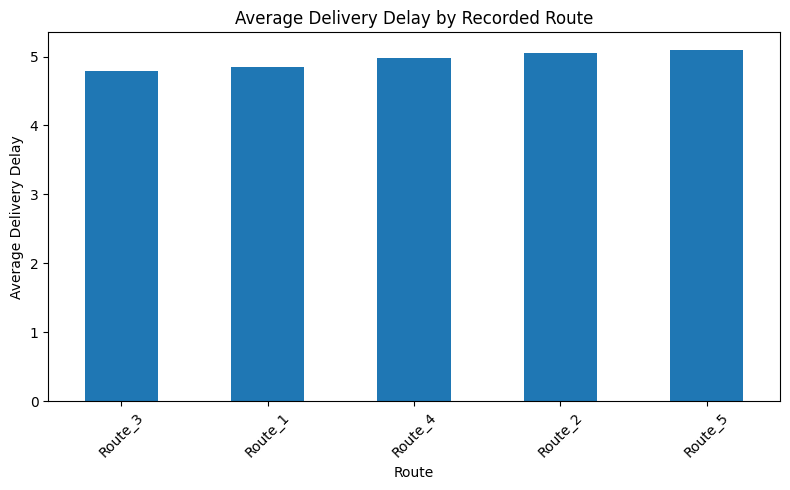

In [ ]:
# Visualize average delivery delay by recorded route
if "route_taken" in df.columns:
    route_taken_delay = (
        df.groupby("route_taken")["delivery_delay"]
          .mean()
          .sort_values()
    )
    route_taken_delay.plot(kind="bar", figsize=(8, 5))
    plt.title("Average Delivery Delay by Recorded Route")
    plt.xlabel("Route")
    plt.ylabel("Average Delivery Delay")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Route-level delay chart skipped: 'route_taken' is not available.")

count    20000.000000
mean        38.925300
std         12.370941
min         18.000000
25%         28.000000
50%         39.000000
75%         50.000000
max         60.000000
Name: age, dtype: float64


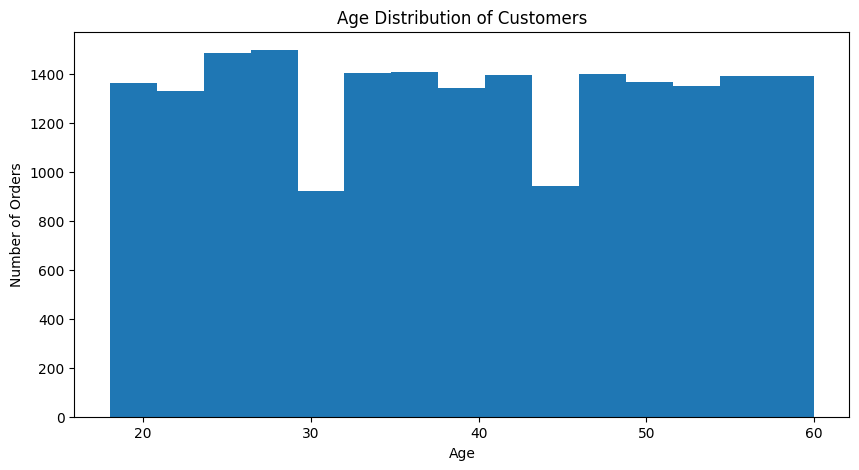

In [ ]:
#CUSTOMER AGE DIETRIBUTION
print(df["age"].describe())
plt.figure(figsize=(10, 5))

plt.hist(df["age"], bins=15)

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Orders")

plt.show()

gender
Other     6778
Female    6656
Male      6566
Name: count, dtype: int64


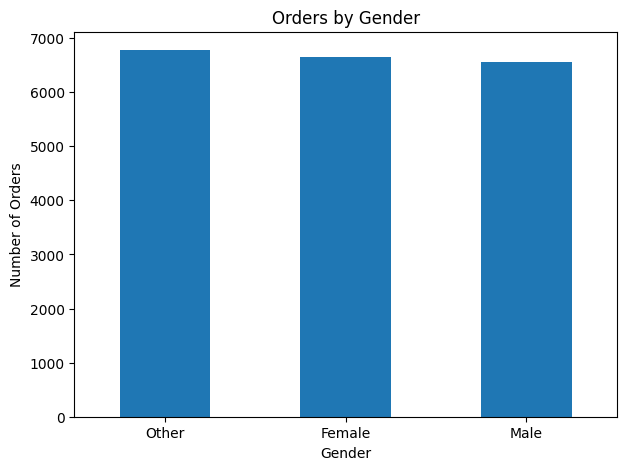

In [ ]:
#GENDER DISTRIBUTION
print(df["gender"].value_counts())
plt.figure(figsize=(7, 5))

df["gender"].value_counts().plot(kind="bar")

plt.title("Orders by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

preferred_cuisine
Asian            4088
Mexican          4024
American         3978
Italian          3960
Mediterranean    3950
Name: count, dtype: int64


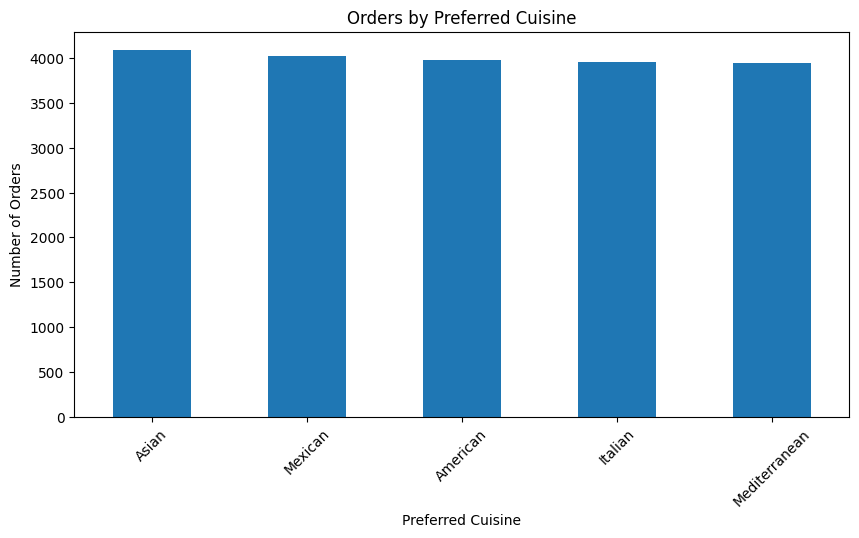

In [ ]:
#PREFFERED CUISINE
cuisine_demand = df["preferred_cuisine"].value_counts()

print(cuisine_demand)
plt.figure(figsize=(10, 5))

cuisine_demand.plot(kind="bar")

plt.title("Orders by Preferred Cuisine")
plt.xlabel("Preferred Cuisine")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#ORDER FREQUENCY
print(df["order_frequency"].value_counts(dropna=False))


order_frequency
Weekly     10038
Monthly     9962
Name: count, dtype: int64


loyalty_program
Yes    10016
No      9984
Name: count, dtype: int64


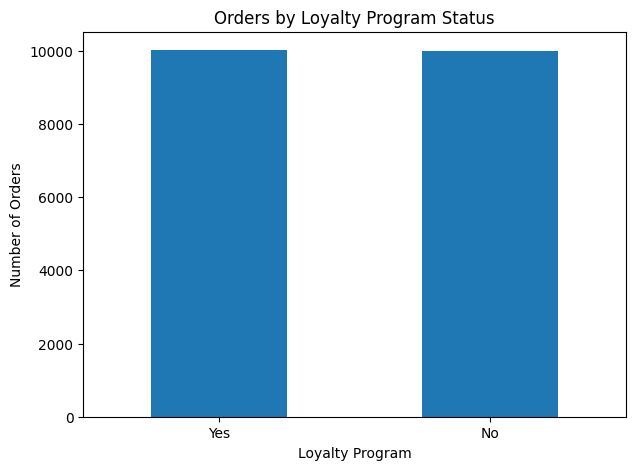

In [ ]:
#LOYALTYPROGRAM
print(df["loyalty_program"].value_counts(dropna=False))
plt.figure(figsize=(7, 5))

df["loyalty_program"].value_counts().plot(kind="bar")

plt.title("Orders by Loyalty Program Status")
plt.xlabel("Loyalty Program")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

customer_rating
1    3924
2    3890
3    4052
4    3994
5    4140
Name: count, dtype: int64


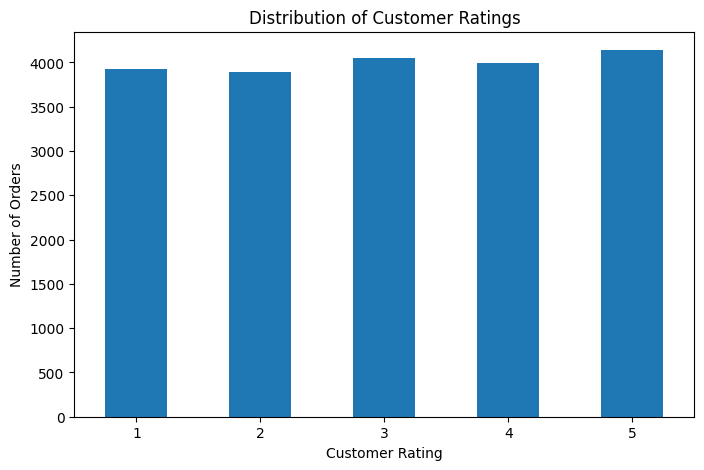

In [ ]:
print(df["customer_rating"].value_counts().sort_index())
plt.figure(figsize=(8, 5))

df["customer_rating"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

In [ ]:
#AVERAGE CUSTOMER RATING
print("Average customer rating:",
      df["customer_rating"].mean())

print("Median customer rating:",
      df["customer_rating"].median())

Average customer rating: 3.0268
Median customer rating: 3.0


count    20000.000000
mean         2.976300
std          1.415217
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: customer_satisfaction, dtype: float64


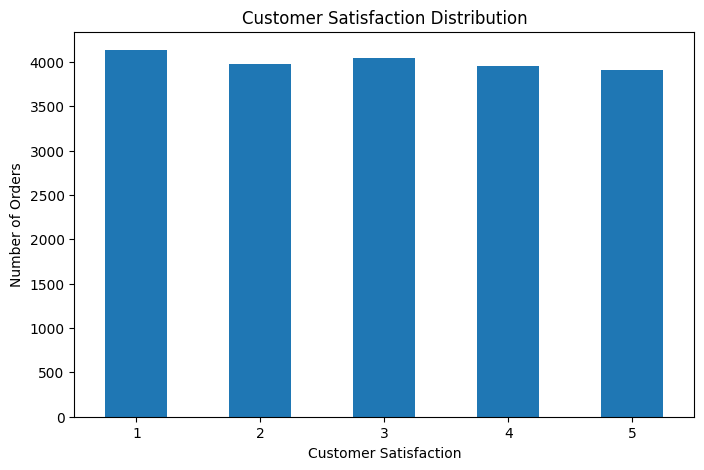

In [ ]:
##CUSTOMER SATISFACTION
print(df["customer_satisfaction"].describe())
plt.figure(figsize=(8, 5))

df["customer_satisfaction"].value_counts().sort_index().plot(kind="bar")

plt.title("Customer Satisfaction Distribution")
plt.xlabel("Customer Satisfaction")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

count    20000.000000
mean         2.991700
std          1.415744
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: food_freshness, dtype: float64


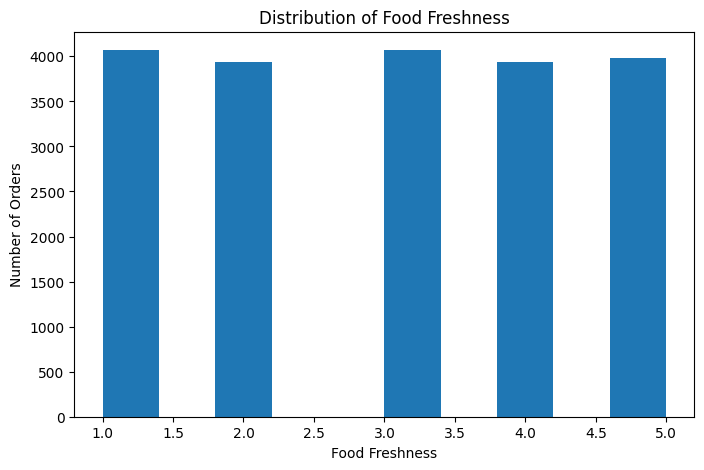

In [ ]:
#FOOD QUALITY ANALYSIS
print(df["food_freshness"].describe())
plt.figure(figsize=(8, 5))

plt.hist(df["food_freshness"], bins=10)

plt.title("Distribution of Food Freshness")
plt.xlabel("Food Freshness")
plt.ylabel("Number of Orders")

plt.show()

count    20000.000000
mean         3.003400
std          1.416929
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: packaging_quality, dtype: float64


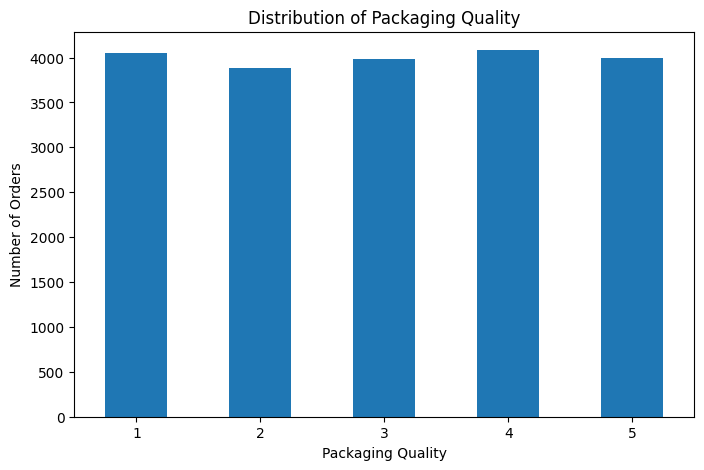

In [ ]:
#PACKAGING QUALITY
print(df["packaging_quality"].describe())
plt.figure(figsize=(8, 5))

df["packaging_quality"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Packaging Quality")
plt.xlabel("Packaging Quality")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

food_temperature
Hot     6744
Cold    6656
Warm    6600
Name: count, dtype: int64


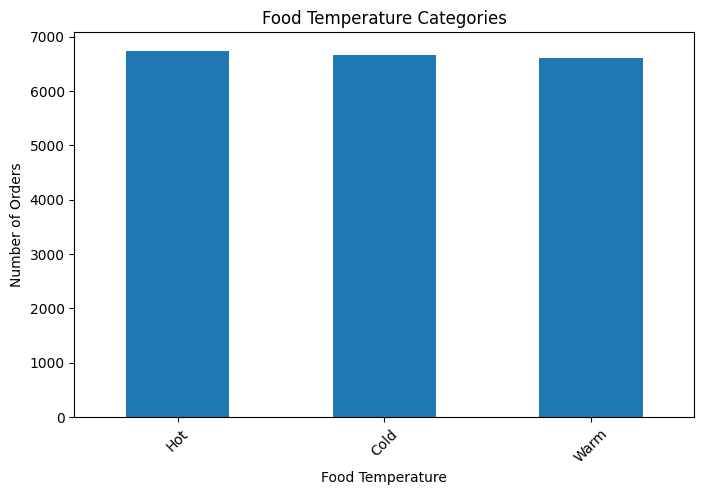

In [ ]:
#FOOD TEMPERATURE
print(df["food_temperature"].value_counts(dropna=False))
plt.figure(figsize=(8, 5))

df["food_temperature"].value_counts().plot(kind="bar")

plt.title("Food Temperature Categories")
plt.xlabel("Food Temperature")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

food_condition
Fair    6728
Good    6642
Poor    6630
Name: count, dtype: int64


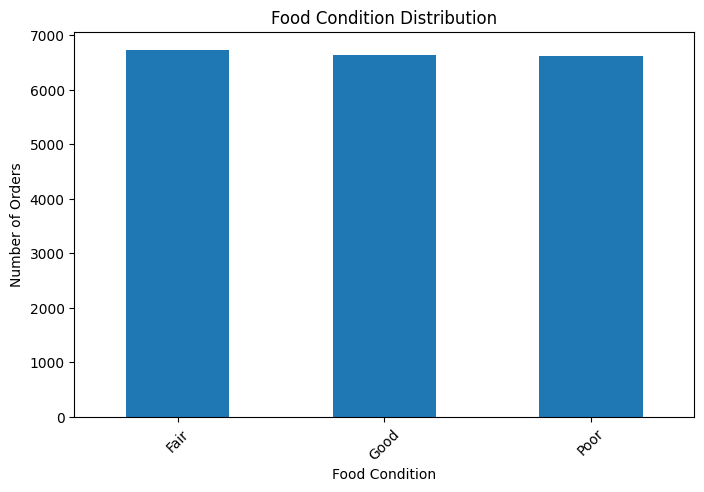

In [ ]:
#FOOD CONDITION
print(df["food_condition"].value_counts(dropna=False))
plt.figure(figsize=(8, 5))

df["food_condition"].value_counts().plot(kind="bar")

plt.title("Food Condition Distribution")
plt.xlabel("Food Condition")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()


food_freshness
1    3.007375
2    2.987303
3    2.950369
4    3.004061
5    2.932731
Name: customer_satisfaction, dtype: float64


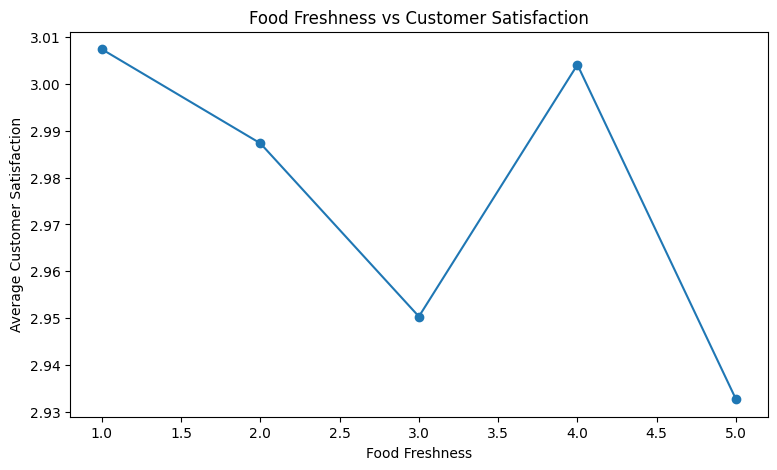

In [ ]:
#CORRECT FOOD QUALITY SATISFACTION
freshness_satisfaction = (
    df.groupby("food_freshness")["customer_satisfaction"]
      .mean()
)

print(freshness_satisfaction)
plt.figure(figsize=(9, 5))

freshness_satisfaction.plot(kind="line", marker="o")

plt.title("Food Freshness vs Customer Satisfaction")
plt.xlabel("Food Freshness")
plt.ylabel("Average Customer Satisfaction")

plt.show()

packaging_quality
1    2.915680
2    3.008754
3    3.009533
4    2.956415
5    2.993484
Name: customer_satisfaction, dtype: float64


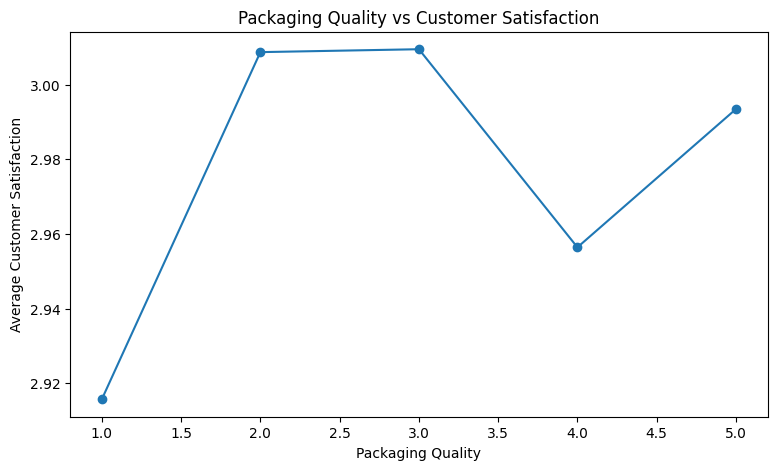

In [ ]:
#PACKAGING QUALITY VERSUS THE SATISFQACTION
packaging_satisfaction = (
    df.groupby("packaging_quality")["customer_satisfaction"]
      .mean()
)

print(packaging_satisfaction)
plt.figure(figsize=(9, 5))

packaging_satisfaction.plot(kind="line", marker="o")

plt.title("Packaging Quality vs Customer Satisfaction")
plt.xlabel("Packaging Quality")
plt.ylabel("Average Customer Satisfaction")

plt.show()


food_condition
Fair    2.939952
Good    2.986450
Poor    3.003017
Name: customer_satisfaction, dtype: float64


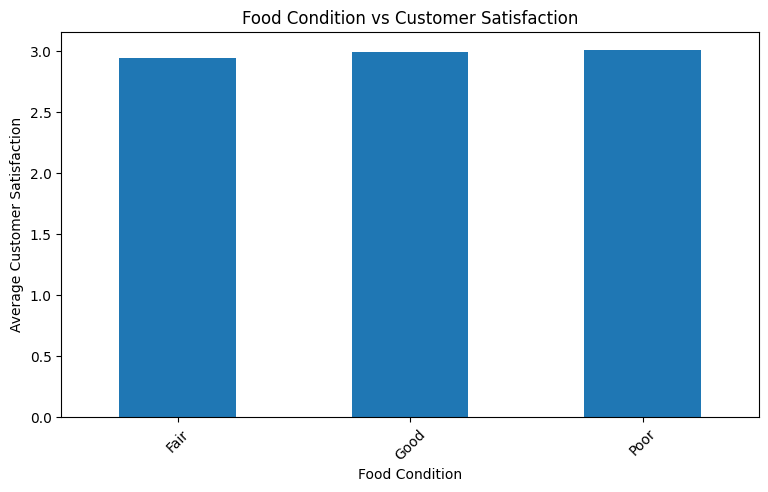

In [ ]:
#FOOD CONDITION VERSUS THE SAISFACTION
condition_satisfaction = (
    df.groupby("food_condition")["customer_satisfaction"]
      .mean()
      .sort_values()
)

print(condition_satisfaction)
plt.figure(figsize=(9, 5))

condition_satisfaction.plot(kind="bar")

plt.title("Food Condition vs Customer Satisfaction")
plt.xlabel("Food Condition")
plt.ylabel("Average Customer Satisfaction")
plt.xticks(rotation=45)

plt.show()

In [ ]:
#DELIVERY EXPERIENCE VERSUS CUSTOMER SATISFACTION
delay_satisfaction = (
    df.groupby("delivery_delay")["customer_satisfaction"]
      .mean()
)

print(delay_satisfaction.head(20))
#CREATING THE DELAY CATEGORIES
def categorize_delay(delay):
    if delay <= 5:
        return "Low Delay"
    elif delay <= 15:
        return "Moderate Delay"
    else:
        return "High Delay"

df["delay_category"] = df["delivery_delay"].apply(categorize_delay)

df[["delivery_delay", "delay_category"]].head(10)


delivery_delay
-10.00    4.000000
-9.99     2.000000
-9.98     3.000000
-9.97     2.000000
-9.96     3.500000
-9.95     2.666667
-9.94     3.200000
-9.93     3.750000
-9.92     2.600000
-9.91     2.500000
-9.90     2.800000
-9.89     3.666667
-9.88     1.666667
-9.87     2.400000
-9.86     2.666667
-9.85     4.000000
-9.84     2.000000
-9.83     1.000000
-9.82     2.400000
-9.81     3.750000
Name: customer_satisfaction, dtype: float64


,delivery_delay,delay_category
0,17.15,High Delay
1,16.04,High Delay
2,9.09,Moderate Delay
3,-2.11,Low Delay
4,12.20,Moderate Delay
5,-0.34,Low Delay
6,0.35,Low Delay
7,-1.31,Low Delay
8,15.55,High Delay
9,9.38,Moderate Delay


delay_category
High Delay        2.957806
Low Delay         2.995036
Moderate Delay    2.957035
Name: customer_satisfaction, dtype: float64


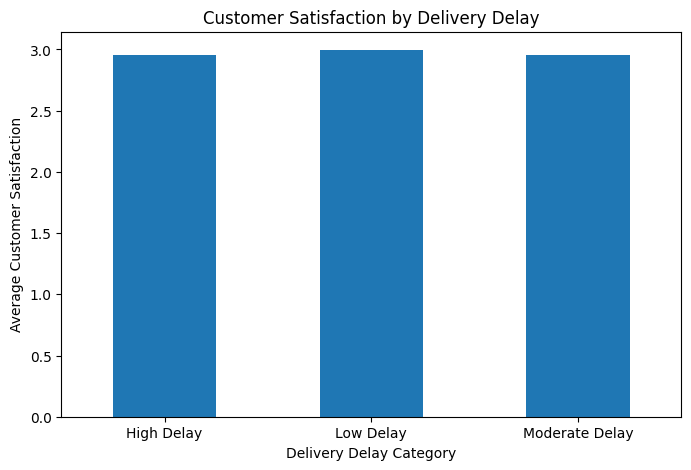

In [ ]:
#DELAY CATEGORY VERSUS THE SATISFACTION
delay_satisfaction = (
    df.groupby("delay_category")["customer_satisfaction"]
      .mean()
)

print(delay_satisfaction)
plt.figure(figsize=(8, 5))

delay_satisfaction.plot(kind="bar")

plt.title("Customer Satisfaction by Delivery Delay")
plt.xlabel("Delivery Delay Category")
plt.ylabel("Average Customer Satisfaction")
plt.xticks(rotation=0)

plt.show()


delay_category
High Delay        3.034961
Low Delay         3.046664
Moderate Delay    2.992436
Name: customer_rating, dtype: float64


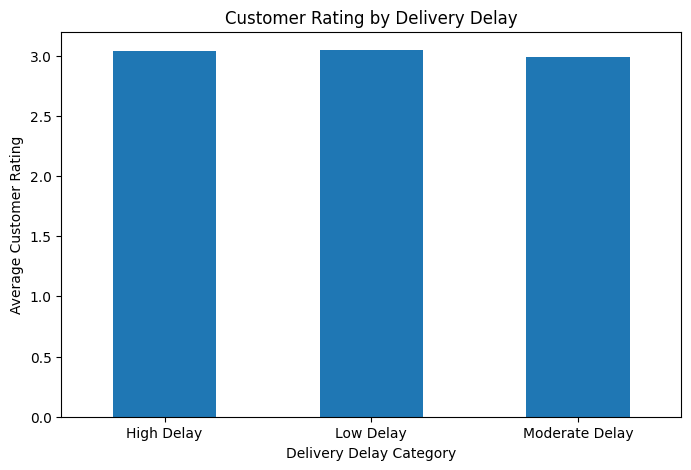

In [ ]:
#DELIVERY DELAY VERSUSTHE RATING
delay_rating = (
    df.groupby("delay_category")["customer_rating"]
      .mean()
)

print(delay_rating)
plt.figure(figsize=(8, 5))

delay_rating.plot(kind="bar")

plt.title("Customer Rating by Delivery Delay")
plt.xlabel("Delivery Delay Category")
plt.ylabel("Average Customer Rating")
plt.xticks(rotation=0)

plt.show()


In [ ]:
#CORRELATION
#IMP
correlation = df["delivery_delay"].corr(df["customer_rating"])

print("Correlation between delivery delay and customer rating:",
      correlation)

Correlation between delivery delay and customer rating: -0.00672209977997551


In [ ]:
#CORELATION MATRIX
correlation_columns = [
    "delivery_distance",
    "order_value",
    "delivery_delay",
    "age",
    "order_history",
    "customer_rating",
    "food_freshness",
    "packaging_quality",
    "customer_satisfaction",
    "route_efficiency"
]

correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix)

,delivery_distance,order_value,delivery_delay,age,order_history,customer_rating,food_freshness,packaging_quality,customer_satisfaction,route_efficiency
delivery_distance,1.000000,0.014585,-0.017554,0.010977,-0.011902,0.008358,-0.005563,-0.003230,-0.015395,-0.008854
order_value,0.014585,1.000000,-0.012772,0.009313,-0.002125,-0.003007,-0.007801,0.020784,0.015042,0.015391
delivery_delay,-0.017554,-0.012772,1.000000,0.000226,-0.005513,-0.006722,0.016920,0.016420,-0.006861,-0.000923
age,0.010977,0.009313,0.000226,1.000000,0.019149,0.006221,0.000301,-0.005685,0.007136,-0.010105
order_history,-0.011902,-0.002125,-0.005513,0.019149,1.000000,0.009450,0.001157,-0.011370,-0.011924,0.000199
customer_rating,0.008358,-0.003007,-0.006722,0.006221,0.009450,1.000000,-0.001535,0.003293,-0.007815,0.000385
food_freshness,-0.005563,-0.007801,0.016920,0.000301,0.001157,-0.001535,1.000000,-0.005420,-0.013325,0.000240
packaging_quality,-0.003230,0.020784,0.016420,-0.005685,-0.011370,0.003293,-0.005420,1.000000,0.010513,0.009012
customer_satisfaction,-0.015395,0.015042,-0.006861,0.007136,-0.011924,-0.007815,-0.013325,0.010513,1.000000,-0.005740
route_efficiency,-0.008854,0.015391,-0.000923,-0.010105,0.000199,0.000385,0.000240,0.009012,-0.005740,1.000000


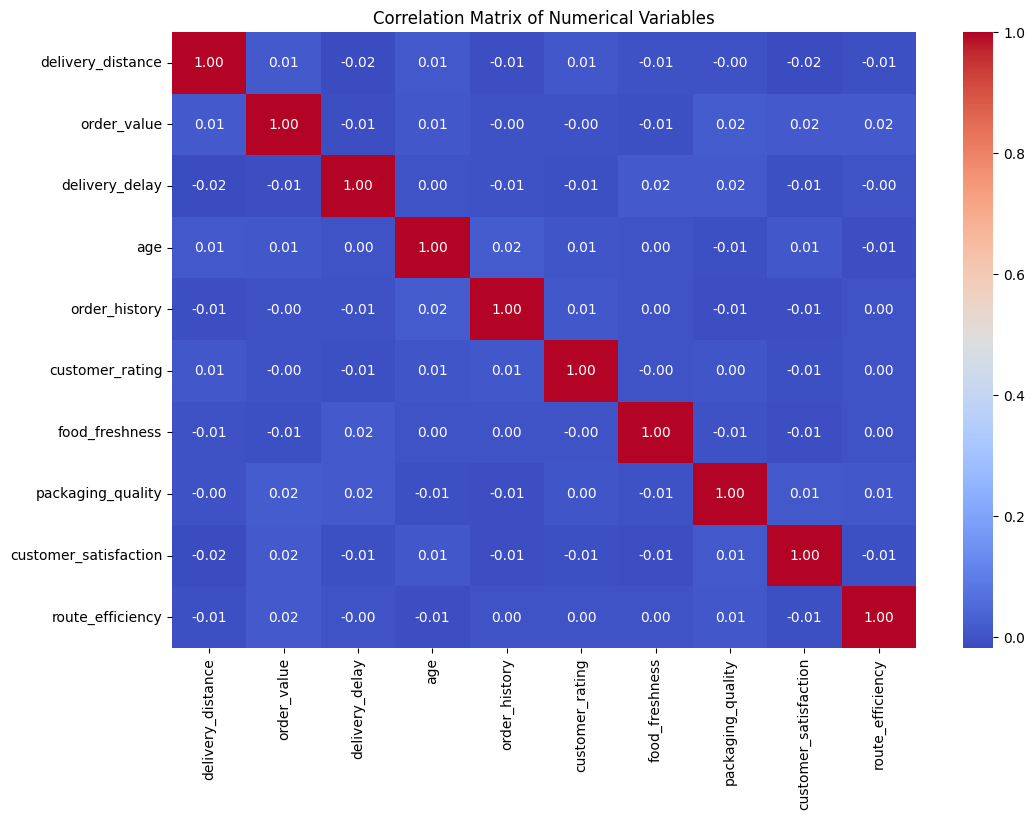

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()

traffic_condition,High,Low,Medium
time_period,,,
Time not available,6528,6772,6700


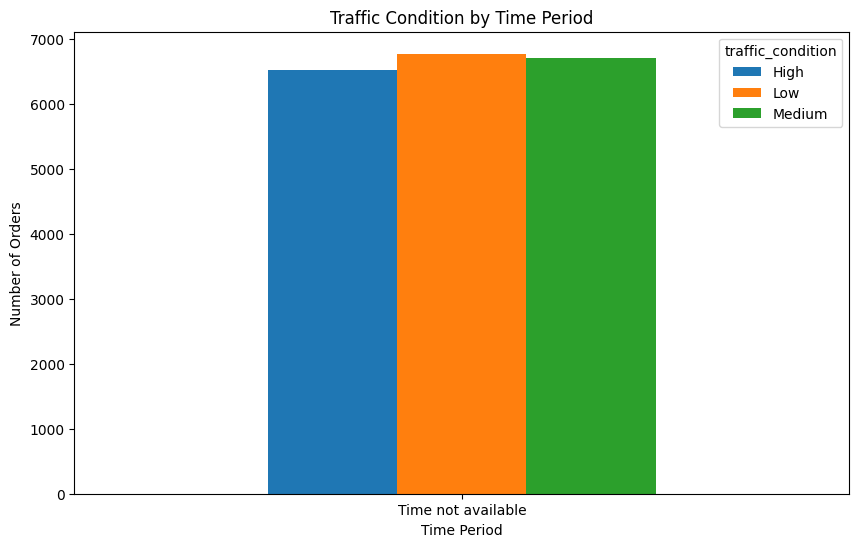

In [ ]:
#TRAFFIC X TIME PERIOD
traffic_time = pd.crosstab(
    df["time_period"],
    df["traffic_condition"]
)#ERROR

display(traffic_time)
traffic_time.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Traffic Condition by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

weather_condition,Rainy,Snowy,Sunny
time_period,,,
Time not available,6600,6728,6672


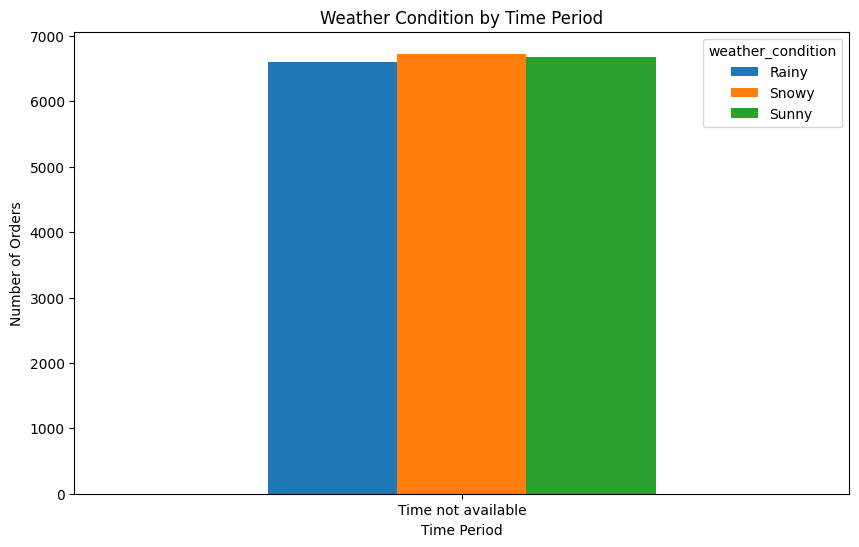

In [ ]:
#WEATHERxTIME PERIOD
weather_time = pd.crosstab(
    df["time_period"],
    df["weather_condition"]#ERROR
)
display(weather_time)
weather_time.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Weather Condition by Time Period")
plt.xlabel("Time Period")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.show()

food_item,Beef pie,Briyani rice,Burger,Burritos,Chicken pie,Chicken rice,Chicken wings,CoffeeBoba tea,Cookie,Cup cake,...,Fried chicken,Pasta,PastrySmoothie,Pizza,Salad,Shawarma,Soup,Sushi,Taccos,Whole cake
location,,,,,,,,,,,,,,,,,,,,,
Ahmedabad,131,101,95,81,85,83,91,89,103,91,...,82,183,91,115,95,91,84,83,93,87
Bangalore,91,87,88,92,87,108,80,91,90,84,...,93,183,83,85,82,100,103,84,82,90
Chennai,87,80,93,82,85,102,110,98,78,99,...,94,195,90,94,98,88,94,76,73,101
Delhi,83,91,85,76,99,96,102,98,74,96,...,77,189,88,97,82,93,106,79,96,117
Hyderabad,94,82,81,88,85,78,92,78,102,87,...,86,180,86,96,101,77,117,94,97,92
Jaipur,86,95,93,91,91,81,95,101,88,102,...,98,216,82,73,94,77,82,104,99,96
Kolkata,89,90,67,85,96,98,87,115,105,93,...,76,175,82,92,104,87,97,100,96,88
Lucknow,92,100,90,69,105,90,80,80,89,88,...,93,189,78,86,78,94,75,83,93,95
Mumbai,78,84,88,100,81,90,94,80,98,104,...,101,191,93,85,95,93,94,84,78,86


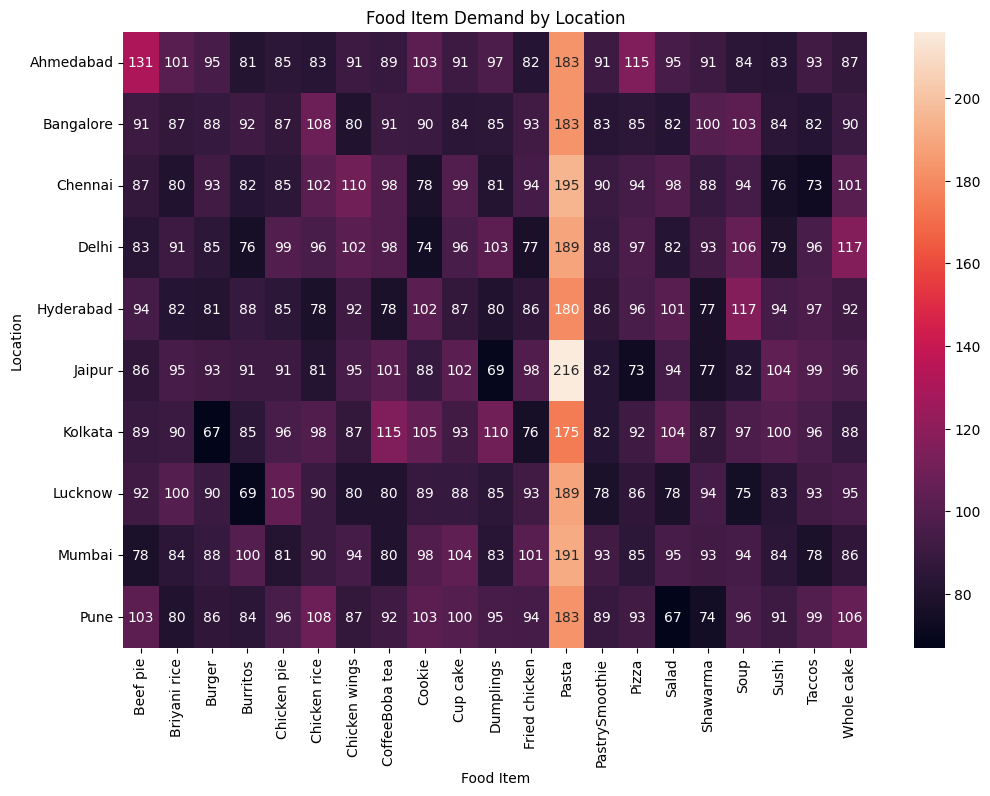

In [ ]:
#LOCATIONXFOOD
location_food = pd.crosstab(
    df["location"],
    df["food_item"]
)

display(location_food)
plt.figure(figsize=(12, 8))

sns.heatmap(
    location_food,
    annot=True,
    fmt="d"
)

plt.title("Food Item Demand by Location")
plt.xlabel("Food Item")
plt.ylabel("Location")

plt.show()

In [ ]:
#CUSTOMER BEHAVIOUR
#LOYALTY X ORDER FREQUENCY
loyalty_frequency = pd.crosstab(
    df["loyalty_program"],
    df["order_frequency"]
)

display(loyalty_frequency)

order_frequency,Monthly,Weekly
loyalty_program,,
No,5014,4970
Yes,4948,5068


In [ ]:
loyalty_frequency_pct = pd.crosstab(
    df["loyalty_program"],
    df["order_frequency"],
    normalize="index"
) * 100

display(loyalty_frequency_pct.round(2))

order_frequency,Monthly,Weekly
loyalty_program,,
No,50.22,49.78
Yes,49.40,50.60


In [ ]:
#LOYALTY X ORDER VALUE
loyalty_value = (
    df.groupby("loyalty_program")["order_value"]
      .agg(["count", "mean", "median"])
)

display(loyalty_value)

,count,mean,median
loyalty_program,,,
No,9984,27.270877,27.050
Yes,10016,27.399097,27.335


In [ ]:
#AGE GRP ANALYSIS
def age_group(age):
    if age < 20:
        return "Under 20"
    elif age < 30:
        return "20-29"
    elif age < 40:
        return "30-39"
    elif age < 50:
        return "40-49"
    else:
        return "50+"

df["age_group"] = df["age"].apply(age_group)

df[["age", "age_group"]].head(10)


,age,age_group
0,32,30-39
1,59,50+
2,20,20-29
3,31,30-39
4,27,20-29
5,53,50+
6,39,30-39
7,30,30-39
8,46,40-49
9,43,40-49


In [ ]:
age_value = (
    df.groupby("age_group")["order_value"]
      .agg(["count", "mean", "median"])
)

display(age_value)#ERROR

,count,mean,median
age_group,,,
20-29,4824,27.222081,26.785
30-39,4628,27.055216,26.910
40-49,4650,27.494292,27.770
50+,5044,27.523779,27.485
Under 20,854,27.508829,27.070


,count,mean,median
age_group,,,
20-29,4824,27.222081,26.785
30-39,4628,27.055216,26.910
40-49,4650,27.494292,27.770
50+,5044,27.523779,27.485
Under 20,854,27.508829,27.070


preferred_cuisine,American,Asian,Italian,Mediterranean,Mexican
age_group,,,,,
20-29,974,1040,934,946,930
30-39,888,926,908,954,952
40-49,878,980,930,930,932
50+,1064,950,1014,972,1044
Under 20,174,192,174,148,166


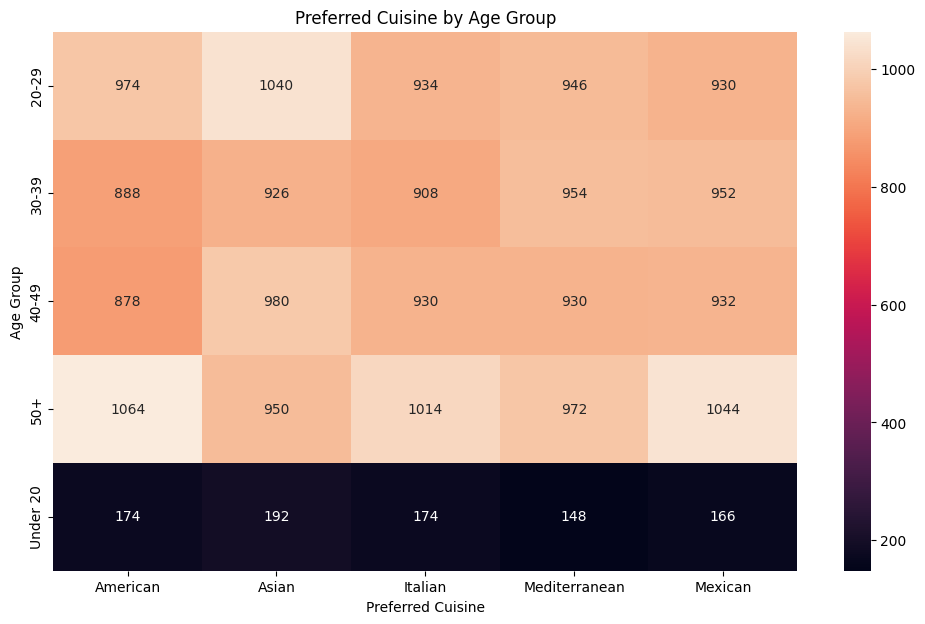

In [ ]:
#AGE GRP X ORDER VALUE
age_value = (
    df.groupby("age_group")["order_value"]
      .agg(["count", "mean", "median"])
)

display(age_value)
#AGE_GRPXCUISINE
age_cuisine = pd.crosstab(
    df["age_group"],
    df["preferred_cuisine"]
)

display(age_cuisine)
plt.figure(figsize=(12, 7))

sns.heatmap(
    age_cuisine,
    annot=True,
    fmt="d"
)

plt.title("Preferred Cuisine by Age Group")
plt.xlabel("Preferred Cuisine")
plt.ylabel("Age Group")

plt.show()


delivery_method,Bike,Car,Walk
traffic_condition,,,
High,4.868400,5.219353,4.851622
Low,5.188452,5.400718,4.604493
Medium,4.802359,5.018132,4.660115


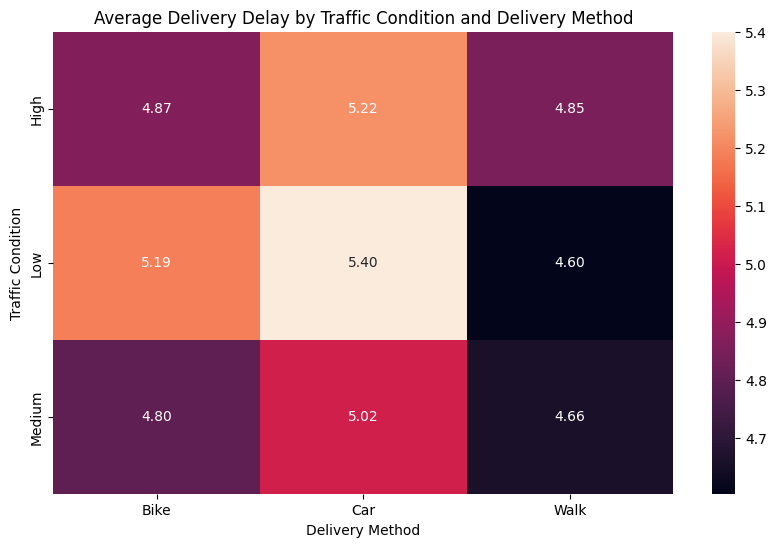

In [ ]:
traffic_method_delay = (
    df.groupby(
        ["traffic_condition", "delivery_method"]
    )["delivery_delay"]
    .mean()
    .unstack()
)

display(traffic_method_delay)
plt.figure(figsize=(10, 6))

sns.heatmap(
    traffic_method_delay,
    annot=True,
    fmt=".2f"
)

plt.title("Average Delivery Delay by Traffic Condition and Delivery Method")
plt.xlabel("Delivery Method")
plt.ylabel("Traffic Condition")

plt.show()

Correlation between route efficiency and delivery delay: -0.0009234684445193133


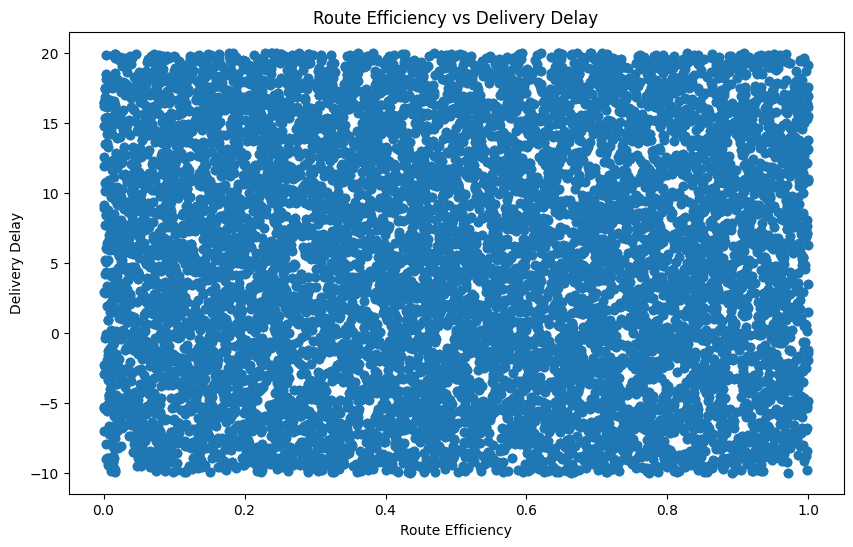

In [ ]:
#ROUTE EFFICIENCY X DELAY
route_correlation = df["route_efficiency"].corr(
    df["delivery_delay"]
)

print(
    "Correlation between route efficiency and delivery delay:",
    route_correlation
)
plt.figure(figsize=(10, 6))

plt.scatter(
    df["route_efficiency"],
    df["delivery_delay"]
)

plt.title("Route Efficiency vs Delivery Delay")
plt.xlabel("Route Efficiency")
plt.ylabel("Delivery Delay")

plt.show()

In [ ]:
# ==========================================
# FINAL KEY ANALYSIS
# ==========================================

print("========== DEMAND ==========")

print("\nOrders by time period:")
print(df["time_period"].value_counts())

print("\nTop 5 food items:")
print(df["food_item"].value_counts().head(5))

print("\nTop 5 locations:")
print(df["location"].value_counts().head(5))


print("\n========== ORDER VALUE ==========")

print("\nAverage order value:",
      round(df["order_value"].mean(), 2))

print("Median order value:",
      round(df["order_value"].median(), 2))

print("Total order value:",
      round(df["order_value"].sum(), 2))


print("\n========== DELIVERY ==========")

print("\nAverage delivery distance:",
      round(df["delivery_distance"].mean(), 2))

print("Average delivery delay:",
      round(df["delivery_delay"].mean(), 2))


print("\nAverage delay by traffic:")
print(
    df.groupby("traffic_condition")["delivery_delay"]
      .mean()
      .round(2)
)


print("\nAverage delay by weather:")
print(
    df.groupby("weather_condition")["delivery_delay"]
      .mean()
      .round(2)
)


print("\n========== CUSTOMER ==========")

print("\nAverage customer rating:",
      round(df["customer_rating"].mean(), 2))

print("Average customer satisfaction:",
      round(df["customer_satisfaction"].mean(), 2))


print("\n========== QUALITY ==========")

print("\nAverage food freshness:",
      round(df["food_freshness"].mean(), 2))

print("Average packaging quality:",
      round(df["packaging_quality"].mean(), 2))


print("\n========== CORRELATIONS ==========")

print(
    "Distance ↔ Delay:",
    round(df["delivery_distance"].corr(df["delivery_delay"]), 3)
)

print(
    "Delay ↔ Rating:",
    round(df["delivery_delay"].corr(df["customer_rating"]), 3)
)

print(
    "Delay ↔ Satisfaction:",
    round(
        df["delivery_delay"].corr(
            df["customer_satisfaction"]
        ), 3
    )
)

print(
    "Route efficiency ↔ Delay:",
    round(
        df["route_efficiency"].corr(
            df["delivery_delay"]
        ), 3
    )
)

print(
    "Freshness ↔ Satisfaction:",
    round(
        df["food_freshness"].corr(
            df["customer_satisfaction"]
        ), 3
    )
)

print(
    "Packaging ↔ Satisfaction:",
    round(
        df["packaging_quality"].corr(
            df["customer_satisfaction"]
        ), 3
    )
)

========== DEMAND ==========

Orders by time period:
time_period
Time not available    20000
Name: count, dtype: int64

Top 5 food items:
food_item
Pasta           1884
Whole cake       958
Soup             948
Cup cake         944
Chicken rice     934
Name: count, dtype: int64

Top 5 locations:
location
Ahmedabad    2051
Kolkata      2032
Delhi        2027
Pune         2026
Jaipur       2013
Name: count, dtype: int64

========== ORDER VALUE ==========

Average order value: 27.34
Median order value: 27.2
Total order value: 546701.8

========== DELIVERY ==========

Average delivery distance: 8.5
Average delivery delay: 4.95

Average delay by traffic:
traffic_condition
High      4.98
Low       5.05
Medium    4.82
Name: delivery_delay, dtype: float64

Average delay by weather:
weather_condition
Rainy    4.87
Snowy    4.95
Sunny    5.03
Name: delivery_delay, dtype: float64

========== CUSTOMER ==========

Average customer rating: 3.03
Average customer satisfaction: 2.98

========== QUALITY

In [ ]:
#STRONGEST CORELATIONS
corr = df[[
    "delivery_distance",
    "order_value",
    "delivery_delay",
    "age",
    "order_history",
    "customer_rating",
    "food_freshness",
    "packaging_quality",
    "customer_satisfaction",
    "route_efficiency"
]].corr()

pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        pairs.append((
            corr.columns[i],
            corr.columns[j],
            corr.iloc[i, j]
        ))

corr_pairs = pd.DataFrame(
    pairs,
    columns=["Variable 1", "Variable 2", "Correlation"]
)

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

corr_pairs = corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(corr_pairs.head(10))

,Variable 1,Variable 2,Correlation,Absolute Correlation
14,order_value,packaging_quality,0.020784,0.020784
24,age,order_history,0.019149,0.019149
1,delivery_distance,delivery_delay,-0.017554,0.017554
20,delivery_delay,food_freshness,0.016920,0.016920
21,delivery_delay,packaging_quality,0.016420,0.016420
7,delivery_distance,customer_satisfaction,-0.015395,0.015395
16,order_value,route_efficiency,0.015391,0.015391
15,order_value,customer_satisfaction,0.015042,0.015042
0,delivery_distance,order_value,0.014585,0.014585
40,food_freshness,customer_satisfaction,-0.013325,0.013325


In [ ]:
#CHECK FOR THE OUTLIERS
important_numeric = [
    "delivery_distance",
    "order_value",
    "delivery_delay",
    "route_efficiency"
]

for col in important_numeric:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} potential outliers"
    )

delivery_distance: 0 potential outliers
order_value: 0 potential outliers
delivery_delay: 0 potential outliers
route_efficiency: 0 potential outliers


In [ ]:
#FINAL DATA QUALITY CHECK
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate order IDs:")
print(df["order_id"].duplicated().sum())

Rows: 20000
Columns: 36

Missing values:
20000

Duplicate rows:
0

Duplicate order IDs:
0


In [ ]:
df.to_csv(
    "food_delivery_analysis_ready.csv",
    index=False
)

print("Analysis-ready dataset saved successfully!")

Analysis-ready dataset saved successfully!


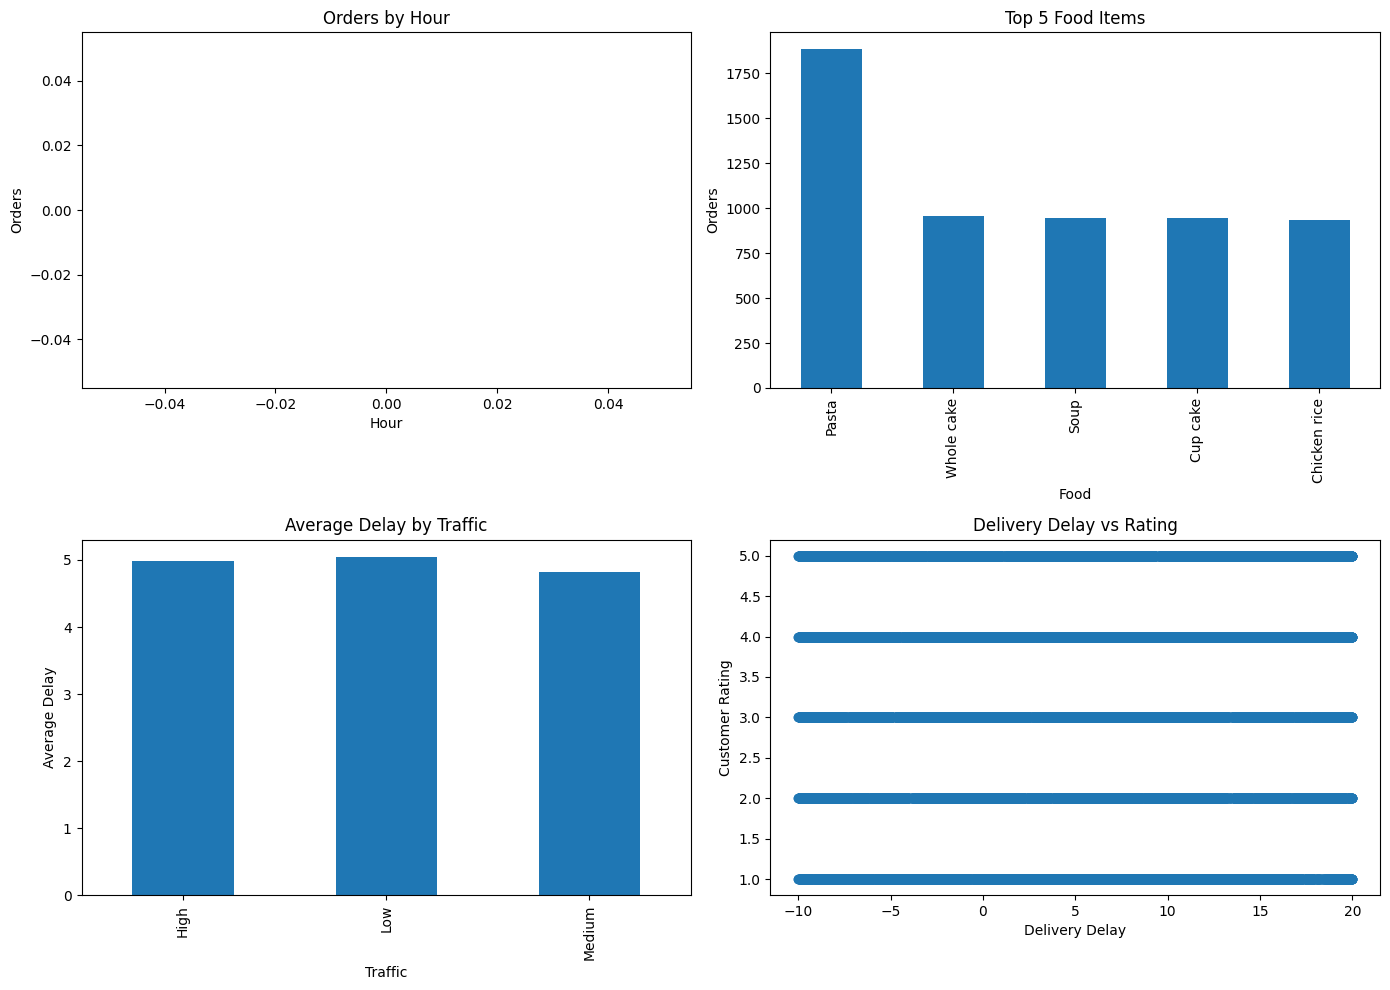

In [ ]:
#FINAL DASHBOARD
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Orders by hour
df["order_hour"].value_counts().sort_index().plot(
    kind="line",
    marker="o",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Orders by Hour")
axes[0, 0].set_xlabel("Hour")
axes[0, 0].set_ylabel("Orders")

# 2. Top food items
df["food_item"].value_counts().head(5).plot(
    kind="bar",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 5 Food Items")
axes[0, 1].set_xlabel("Food")
axes[0, 1].set_ylabel("Orders")

# 3. Traffic vs delay
df.groupby("traffic_condition")["delivery_delay"].mean().plot(
    kind="bar",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Delay by Traffic")
axes[1, 0].set_xlabel("Traffic")
axes[1, 0].set_ylabel("Average Delay")

# 4. Delay vs rating
axes[1, 1].scatter(
    df["delivery_delay"],
    df["customer_rating"]
)
axes[1, 1].set_title("Delivery Delay vs Rating")
axes[1, 1].set_xlabel("Delivery Delay")
axes[1, 1].set_ylabel("Customer Rating")

plt.tight_layout()
plt.show()

In [ ]:
# FINAL DATASET CHECK

print("========== FINAL DATASET CHECK ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate order IDs:")
print(df["order_id"].duplicated().sum())

print("\nData types:")
print(df.dtypes)

========== FINAL DATASET CHECK ==========
Rows: 20000
Columns: 36

Missing values:
20000

Duplicate rows:
0

Duplicate order IDs:
0

Data types:
order_id                         object
restaurant_id                     int64
food_item                        object
order_time               datetime64[ns]
delivery_time            datetime64[ns]
delivery_distance               float64
order_value                     float64
delivery_method                  object
traffic_condition                object
weather_condition                object
delivery_delay                  float64
route_taken                      object
customer_id                      object
age                               int64
gender                           object
location                         object
order_history                     int64
customer_rating                   int64
preferred_cuisine                object
order_frequency                  object
loyalty_program                  object
food_temperatur

In [ ]:
from google.colab import files

files.download("food_delivery_analysis_ready.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>